# Análisis Exploratorio de Datos - DataCo Smart Supply Chain

Este proyecto tiene como objetivo realizar un análisis exploratorio del dataset DataCo Smart Supply Chain, con el propósito de conocer la estructura y calidad de los datos e identificar patrones relevantes relacionados con las ventas, clientes, productos, pedidos y logística.


In [94]:
#Importamos las Librerías necesarias:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [95]:
#cargamos el el dataset en un DataFrame de Pandas 

df = pd.read_csv(
    r"..\data\raw\DataCoSupplyChainDataset.csv",
    encoding="latin-1"
)

In [96]:
# Normalizamos los nombres de las columnas para trabajar con un formato uniforme (minúsculas y snake_case)
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)



In [97]:
# Limpiamos espacios sobrantes de los valores de texto antes de comenzar la exploración
columnas_texto = df.select_dtypes(include=["object", "string"]).columns

for col in columnas_texto:
    df[col] = df[col].str.strip().str.replace(r"\s+", " ", regex=True)

##  1 Exploración inicial

Una vez cargados los datos, se realiza una primera inspección para comprobar su contenido y conocer la estructura general del dataset.

In [98]:
#mostramos las primeras filas del dataset:
df.head()

,type,days_for_shipping_real,days_for_shipment_scheduled,benefit_per_order,sales_per_customer,delivery_status,late_delivery_risk,category_id,category_name,customer_city,...,order_zipcode,product_card_id,product_category_id,product_description,product_image,product_name,product_price,product_status,shipping_date_dateorders,shipping_mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [99]:
# Dimensiones e información general del dataset:
print(f"Dimensiones del dataset: {df.shape}")
df.info()


Dimensiones del dataset: (180519, 53)
<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   type                         180519 non-null  str    
 1   days_for_shipping_real       180519 non-null  int64  
 2   days_for_shipment_scheduled  180519 non-null  int64  
 3   benefit_per_order            180519 non-null  float64
 4   sales_per_customer           180519 non-null  float64
 5   delivery_status              180519 non-null  str    
 6   late_delivery_risk           180519 non-null  int64  
 7   category_id                  180519 non-null  int64  
 8   category_name                180519 non-null  str    
 9   customer_city                180519 non-null  str    
 10  customer_country             180519 non-null  str    
 11  customer_email               180519 non-null  str    
 12  customer_fname               18

### Análisis de valores nulos

Se comprueba la presencia de valores nulos en las diferentes variables del dataset para conocer su distribución y determinar posteriormente cómo deben tratarse durante la fase de limpieza.

In [100]:
# comprobar número de valores nulos por columna:

df.isnull().sum()

type                                0
days_for_shipping_real              0
days_for_shipment_scheduled         0
benefit_per_order                   0
sales_per_customer                  0
delivery_status                     0
late_delivery_risk                  0
category_id                         0
category_name                       0
customer_city                       0
customer_country                    0
customer_email                      0
customer_fname                      0
customer_id                         0
customer_lname                      8
customer_password                   0
customer_segment                    0
customer_state                      0
customer_street                     0
customer_zipcode                    3
department_id                       0
department_name                     0
latitude                            0
longitude                           0
market                              0
order_city                          0
order_countr

Como podemos observar, el análisis muestra que la mayoría de campos no tienen valores nulos. Sinembargo hay columnas como **"product_description"** que todo son nulos, por lo que es innecesaria y se puede eliminar. 

la columna **"order_zipcode"** tambien tiene un número significativo de nulos, por lo que habría que valorar si nos aporta o es posible eliminarla del estudio.

**"Customer Lname"** presenta únicamente 8 valores ausentes y **"Customer Zipcode"** 3, cantidades muy reducidas respecto a los 180.519 registros del dataset. Por tanto, su impacto sobre el conjunto de datos es prácticamente insignificante.

### Análisis de duplicados:

Se comprueba la existencia de registros duplicados para determinar si existen observaciones repetidas que puedan afectar a la calidad y consistencia del análisis.

In [101]:
# comprobamos la existencia de registros duplicados en el dataset:
df.duplicated().sum()

np.int64(0)

El análisis muestra que hay un total de 0 duplicados, por lo que no hay que tratarlos en la limpieza y preparación de los mismos.

## 2 Limpieza y preparación de los datos:

Una vez realizada la exploración inicial, se procede a preparar el conjunto de datos para el análisis. En esta fase se revisarán y corregirán los tipos de datos, se tratarán los valores ausentes y se comprobará la consistencia de las variables. 

El objetivo de esta fase es dotar de la mayor calidad posible a los datos disponibles.


### 2.1 Corrección de tipos de datos:

A partir de la inspección inicial se han identificado variables cuya naturaleza no coincide con el tipo de dato asignado. En particular, las variables correspondientes a las fechas de pedido y envío se encuentran almacenadas como texto.

Estas variables se convertirán al formato de fecha (datetime) para permitir posteriormente operaciones temporales y análisis de la evolución de las ventas y de los pedidos.


In [102]:
# cambio de tipo de formato en las columnas "order_date_dateorders" y "shipping_date_dateorders" 
# (de str a datetime)

df["order_date_dateorders"] = pd.to_datetime(
    df["order_date_dateorders"],
    errors="coerce"
)

df["shipping_date_dateorders"] = pd.to_datetime(
    df["shipping_date_dateorders"],
    errors="coerce"
)

In [103]:
# comprobación del cambio de tipo:
df[["order_date_dateorders", "shipping_date_dateorders"]].dtypes

order_date_dateorders       datetime64[us]
shipping_date_dateorders    datetime64[us]
dtype: object

Podemos identificar variables categóricas que presentan un número reducido de categorías  por lo que se convertirán al tipo "category".

No todas las variables categóricas se convertirán a este tipo, solo las que nos interesan(dejamos fuera nombres, correos electrónicos, direcciones...).

Las variables binarias "late_delivery_risk" y "product_status" se mantienen como variables numéricas ("int64") debido a su codificación 0/1, que facilita el cálculo posterior de proporciones e indicadores.

In [104]:
# Cambio de tipo de datos en las variables categóricas seleccionadas (de str  a category):

categorical_columns = [ "delivery_status",
    "customer_segment",
    "market",
    "order_region",
    "order_status",
    "shipping_mode"]
for col in categorical_columns:
    df[col] = df[col].astype("category")


In [105]:
#comprobamos que se han convertido los tipos de las variables categóricas adecuadamente:

df[categorical_columns].dtypes

delivery_status     category
customer_segment    category
market              category
order_region        category
order_status        category
shipping_mode       category
dtype: object

###  2.2 Trato de valores nulos:

Tras la inspección inicial se identificaron valores ausentes en cuatro variables: "Customer Lname", "Customer Zipcode", "order_zipcode" y "product_description".

Antes de aplicar cualquier tratamiento, se analizará la cantidad y proporción de valores ausentes de cada variable para determinar la estrategia más adecuada en cada caso. Se evitará eliminar información de forma generalizada, valorando la importancia de cada variable para el análisis y el porcentaje de datos ausentes que presenta.

In [106]:
#obtenemos porcetnaje de nulos por columna:
missing = df.isna().sum()

missing_percentage = (missing / len(df))*100

# creamos una tabla o dataframe que enseñe el porcentaje y los nulos por variable, si esque los hay:

missing_summary = pd.DataFrame({
    "Nulos": missing,
    "%": missing_percentage
})

#mostramos la tabla de nulos y porcentaje :

round(missing_summary[missing_summary["Nulos"] > 0], 2)

,Nulos,%
customer_lname,8,0.00
customer_zipcode,3,0.00
order_zipcode,155679,86.24
product_description,180519,100.00


Procedemos a tratar los nulos en cuestión:

- product_description: Esta columna tiene un 100 % de nulos, por lo que no aporta información y resta calidad al dataset, por lo que conviene eliminar dicha columna.

In [107]:
#eliminar columnas innecesaria:

df.drop(columns=["product_description"], inplace=True)

- order_zipcode: Este campo tiene más de un 86% de nulos. Aunque existen códigos postales en los registros disponibles, la elevada proporción de valores ausentes impide realizar una imputación fiable.
 Además, el conjunto de datos dispone de otras variables geográficas, como ciudad, estado,region etc... que permiten realizar el análisis geográfico sin necesidad de utilizar el código postal. Por este motivo, se decide eliminar esta variable.

In [108]:
df.drop(columns=["order_zipcode"], inplace=True)


La variable "Customer Lname" presenta únicamente 8 valores ausentes, lo que representa el 0,0044 % del total de registros. Debido a su proporción insignificante y a que no es posible determinar de forma fiable los apellidos que faltan, se mantienen estos valores como ausentes ("NaN").

No se eliminan los registros ni se realiza una imputación, ya que no supondría una mejora relevante para el análisis.

Con la variable "Customer Zipcode" pasa lo mismo, es un dato desconocido e insignificante que se mantiene como "NaN" o desconocido.

### 2.3 Comprobación final de las variables categóricas y binarias:

Comprobamos si las variables tienen las categorías que deben y si no hay ninguna falla:

In [109]:
for col in categorical_columns:
    print(f"\n{col} ({df[col].nunique()} categorías):")
    print(df[col].unique())


delivery_status (4 categorías):
['Advance shipping', 'Late delivery', 'Shipping on time', 'Shipping canceled']
Categories (4, str): ['Advance shipping', 'Late delivery', 'Shipping canceled', 'Shipping on time']

customer_segment (3 categorías):
['Consumer', 'Home Office', 'Corporate']
Categories (3, str): ['Consumer', 'Corporate', 'Home Office']

market (5 categorías):
['Pacific Asia', 'USCA', 'Africa', 'Europe', 'LATAM']
Categories (5, str): ['Africa', 'Europe', 'LATAM', 'Pacific Asia', 'USCA']

order_region (23 categorías):
['Southeast Asia', 'South Asia', 'Oceania', 'Eastern Asia', 'West Asia', ..., 'Canada', 'Southern Africa', 'Central Asia', 'Eastern Europe', 'South of USA']
Length: 23
Categories (23, str): ['Canada', 'Caribbean', 'Central Africa', 'Central America', ..., 'West Africa', 'West Asia', 'West of USA', 'Western Europe']

order_status (9 categorías):
['COMPLETE', 'PENDING', 'CLOSED', 'PENDING_PAYMENT', 'CANCELED', 'PROCESSING', 'SUSPECTED_FRAUD', 'ON_HOLD', 'PAYMENT_RE

In [110]:
# comprobamos tambien las variables binarias:

binary_columns = [
    "late_delivery_risk",
    "product_status"
]

for col in binary_columns:
    print(f"\n{col}:")
    print(df[col].unique())


late_delivery_risk:
[0 1]

product_status:
[0]


In [111]:
df["product_status"].value_counts()

product_status
0    180519
Name: count, dtype: int64

Observamos que la variable product_status solo tiene 0, es decir, que hay existencia de todos los porductos, no hay ninguno sin stock. No hay valores incorrectos ni necesidad de eliminar la columna.

## 2.4 estadística desciptiva y anomalías:

Aquí nos centramos en describir las variables numéricas y detectar posibles valores que merezcan revisión.

In [112]:
df.describe()

,days_for_shipping_real,days_for_shipment_scheduled,benefit_per_order,sales_per_customer,late_delivery_risk,category_id,customer_id,customer_zipcode,department_id,latitude,...,order_item_profit_ratio,order_item_quantity,sales,order_item_total,order_profit_per_order,product_card_id,product_category_id,product_price,product_status,shipping_date_dateorders
count,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180516.000000,180519.000000,180519.000000,...,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.0,180519
mean,3.497654,2.931847,21.974989,183.107609,0.548291,31.851451,6691.379495,35921.126914,5.443460,29.719955,...,0.120647,2.127638,203.772096,183.107609,21.974989,692.509764,31.851451,141.232550,0.0,2016-06-16 05:45:23.202433
min,0.000000,0.000000,-4274.979980,7.490000,0.000000,2.000000,1.000000,603.000000,2.000000,-33.937553,...,-2.750000,1.000000,9.990000,7.490000,-4274.979980,19.000000,2.000000,9.990000,0.0,2015-01-03 00:00:00
25%,2.000000,2.000000,7.000000,104.379997,0.000000,18.000000,3258.500000,725.000000,4.000000,18.265432,...,0.080000,1.000000,119.980003,104.379997,7.000000,403.000000,18.000000,50.000000,0.0,2015-09-25 06:59:00
50%,3.000000,4.000000,31.520000,163.990005,1.000000,29.000000,6457.000000,19380.000000,5.000000,33.144863,...,0.270000,1.000000,199.919998,163.990005,31.520000,627.000000,29.000000,59.990002,0.0,2016-06-15 08:32:00
75%,5.000000,4.000000,64.800003,247.399994,1.000000,45.000000,9779.000000,78207.000000,7.000000,39.279617,...,0.360000,3.000000,299.950012,247.399994,64.800003,1004.000000,45.000000,199.990005,0.0,2017-03-04 21:29:00
max,6.000000,4.000000,911.799988,1939.989990,1.000000,76.000000,20757.000000,99205.000000,12.000000,48.781933,...,0.500000,5.000000,1999.989990,1939.989990,911.799988,1363.000000,76.000000,1999.989990,0.0,2018-02-06 22:14:00
std,1.623722,1.374449,104.433526,120.043670,0.497664,15.640064,4162.918106,37542.461122,1.629246,9.813646,...,0.466796,1.453451,132.273077,120.043670,104.433526,336.446807,15.640064,139.732492,0.0,NaN


La estadística descriptiva permite obtener una primera visión de la distribución de las variables numéricas mediante medidas como la media, la mediana, los valores mínimos y máximos y los cuartiles.

A partir de los resultados obtenidos, se observan algunos valores que requieren una revisión específica, especialmente en las variables relacionadas con la rentabilidad, como "benefit_per_order" y "order_item_profit_ratio", debido a la presencia de valores negativos. Estos valores no se consideran inicialmente errores, ya que pueden representar operaciones que hayan generado pérdidas, por lo que se comprobarán antes de realizar cualquier tratamiento.

In [113]:
#Comprobamos cuantos pedidos con beneficio negativo tenemos
(df["benefit_per_order"] < 0).sum()

np.int64(33784)

In [114]:
#porcentaje de pedidos con beneficio negativo:

negative_benefit_percentage = (df["benefit_per_order"] < 0).sum() / len(df) * 100

negative_benefit_percentage

np.float64(18.714927514555253)

Los resultados muestran que 33.784 registros, equivalentes al 18,71 % del total, presentan un "benefit_per_order" negativo. Estos valores no se consideran errores, ya que un beneficio negativo puede representar operaciones que hayan generado pérdidas.

In [115]:
# Comprobamos cuántos registros presentan un order_item_profit_ratio negativo:
(df["order_item_profit_ratio"] < 0).sum()

np.int64(33784)

In [116]:
# Calculamos el porcentaje de registros con order_item_profit_ratio negativo:
negative_profit_ratio_percentage = (df["order_item_profit_ratio"] < 0).sum() / len(df) * 100

negative_profit_ratio_percentage

np.float64(18.714927514555253)

Que coincida el número encaja, porque los registros que presentan un beneficio negativo deberían estar asociados a un ratio de beneficio negativo. Todo indica a que estos números negativos corresponden a pérdidas.

## Comprobación final de la limpieza y tratamiento de datos:

In [117]:
# Comprobación final de la limpieza:

print("Dimensiones del dataset:", df.shape)
print("\nDuplicados:", df.duplicated().sum())
print("\nValores nulos:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nTipos de datos:")
print(df.dtypes)

Dimensiones del dataset: (180519, 51)

Duplicados: 0

Valores nulos:
customer_lname      8
customer_zipcode    3
dtype: int64

Tipos de datos:
type                                      str
days_for_shipping_real                  int64
days_for_shipment_scheduled             int64
benefit_per_order                     float64
sales_per_customer                    float64
delivery_status                      category
late_delivery_risk                      int64
category_id                             int64
category_name                             str
customer_city                             str
customer_country                          str
customer_email                            str
customer_fname                            str
customer_id                             int64
customer_lname                            str
customer_password                         str
customer_segment                     category
customer_state                            str
customer_street              

### Conclusión de la limpieza y preparación

Tras realizar la limpieza y preparación del conjunto de datos, se mantienen 180.519 registros y 51 variables. No se han identificado registros duplicados. Se han corregido los tipos de datos de las variables de fecha y se han transformado a tipo categórico aquellas variables seleccionadas para su posterior análisis.

Los valores ausentes restantes corresponden únicamente a 8 registros de "Customer Lname" y 3 de "Customer Zipcode", por lo que se mantienen al representar una proporción mínima del conjunto de datos y no afectar a los análisis principales. Asimismo, los valores negativos detectados en las variables relacionadas con la rentabilidad se mantienen al considerarse compatibles con operaciones que hayan generado pérdidas.

Con estas comprobaciones, el conjunto de datos queda preparado para comenzar el análisis exploratorio de los datos.

Ahora guardamos el df limpio en la carpeta procesed.

In [118]:
# Guardamos el dataset limpio:
df.to_csv(r"..\data\processed\DataCoSupplyChain_clean.csv", index=False)

## 3 Análisis exploratorio profundo
Una vez completada la limpieza y preparación del conjunto de datos, se realiza un análisis exploratorio más detallado con el objetivo de identificar posibles relaciones, patrones y tendencias relevantes.

El análisis se centrará en aquellas variables que puedan aportar información de interés para el negocio, especialmente en aspectos relacionados con las ventas, la rentabilidad y el rendimiento de los envíos.

### 3.1 Análisis de ventas
En este apartado se analiza el comportamiento de las ventas para conocer su evolución a lo largo del periodo estudiado y su distribución entre las principales categorías y mercados. El objetivo es identificar tendencias y determinar qué áreas concentran un mayor volumen de ventas.

### Ventas por mes 

In [119]:
# Agrupamos las ventas por mes:

ventas_mensuales = (
    df.groupby(df["order_date_dateorders"].dt.to_period("M"))["sales"]
    .sum()
)

# Mostrar las ventas con formato legible
print(ventas_mensuales.round(0).map(lambda x: f"{x:,.0f}"))

order_date_dateorders
2015-01    1,051,590
2015-02      927,010
2015-03    1,051,254
2015-04    1,014,463
2015-05    1,050,478
2015-06    1,024,006
2015-07    1,038,081
2015-08    1,029,495
2015-09    1,018,339
2015-10    1,049,154
2015-11    1,029,120
2015-12    1,057,841
2016-01    1,046,308
2016-02      968,543
2016-03    1,025,853
2016-04    1,001,212
2016-05    1,029,400
2016-06    1,003,060
2016-07    1,045,716
2016-08    1,048,200
2016-09    1,002,397
2016-10    1,048,131
2016-11    1,047,590
2016-12    1,037,408
2017-01    1,029,698
2017-02      992,535
2017-03    1,048,005
2017-04    1,038,322
2017-05    1,105,485
2017-06    1,032,086
2017-07    1,104,373
2017-08    1,109,337
2017-09    1,143,775
2017-10    1,073,994
2017-11      626,914
2017-12      503,911
2018-01      331,650
Freq: M, Name: sales, dtype: str


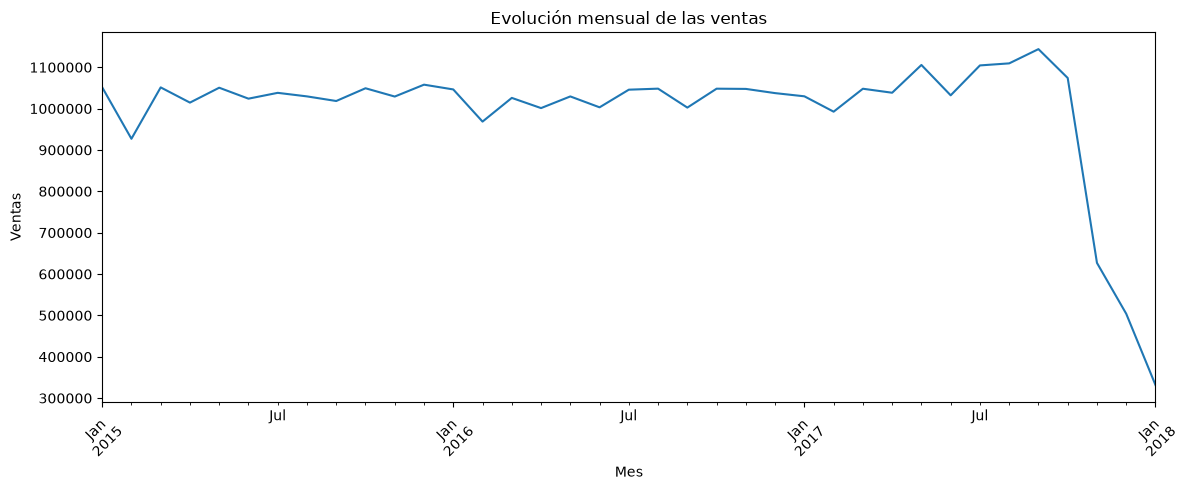

In [120]:
# Gráfico de evolución mensual de las ventas

plt.figure(figsize=(12, 5))

ventas_mensuales.plot(kind="line")

plt.title("Evolución mensual de las ventas")
plt.xlabel("Mes")
plt.ylabel("Ventas")

plt.xticks(rotation=45)

plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

El gráfico muestra una evolución relativamente estable de las ventas durante la mayor parte del periodo analizado, con valores cercanos al millón de unidades monetarias mensuales. Sin embargo, a partir de noviembre de 2017 se observa una disminución notable, que se acentúa durante diciembre de 2017 y enero de 2018.

Para determinar si esta caída de las ventas refleja realmente un menor volumen de actividad, se analizará el número de registros correspondiente a cada mes. Si el número de registros también disminuye en los últimos meses, será necesario tener en cuenta esta circunstancia antes de interpretar la evolución de las ventas.

In [121]:
# Número de registros por mes

registros_mensuales = (
    df.groupby(df["order_date_dateorders"].dt.to_period("M"))
    .size()
)

print(registros_mensuales)

order_date_dateorders
2015-01    5322
2015-02    4729
2015-03    5362
2015-04    5126
2015-05    5357
2015-06    5134
2015-07    5299
2015-08    5273
2015-09    5140
2015-10    5302
2015-11    5235
2015-12    5371
2016-01    5317
2016-02    4894
2016-03    5210
2016-04    5097
2016-05    5302
2016-06    5054
2016-07    5305
2016-08    5334
2016-09    5160
2016-10    5398
2016-11    5210
2016-12    5269
2017-01    5217
2017-02    4906
2017-03    5347
2017-04    5212
2017-05    5317
2017-06    4951
2017-07    5318
2017-08    5305
2017-09    5189
2017-10    2255
2017-11    2055
2017-12    2124
2018-01    2123
Freq: M, dtype: int64


Los resultados muestran que la caída de las ventas a partir de noviembre de 2017 coincide con una reducción importante del número de registros. Durante la mayor parte del periodo se registran alrededor de 5.000 registros al mes, mientras que en noviembre de 2017 esta cifra baja hasta 2.055 y se mantiene en niveles similares durante diciembre y enero.

Por tanto, la caída de las ventas parece estar relacionada con el menor número de operaciones registradas en estos últimos meses, es decir, una menor actividad comercial.

### Ventas por Categoría



A continuación, se analizarán las ventas según la categoría de producto para identificar cuáles concentran un mayor volumen de ventas.

In [122]:

# Ventas totales por categoría

ventas_categoria = (
    df.groupby("category_name", observed=True)["sales"]
    .sum()
    .sort_values(ascending=False)
)

print(ventas_categoria.round(0).map(lambda x: f"{x:,.0f}"))

category_name
Fishing                 6,929,654
Cleats                  4,431,943
Camping & Hiking        4,118,426
Cardio Equipment        3,694,843
Women's Apparel         3,147,800
Water Sports            3,113,845
Men's Footwear          2,891,758
Indoor/Outdoor Games    2,888,994
Shop By Sport           1,309,522
Computers                 663,000
Electronics               371,035
Cameras                   267,608
Garden                    257,769
Children's Clothing       232,829
Crafts                    223,356
Girls' Apparel            151,706
Women's Clothing          140,283
Accessories               133,672
Sporting Goods            117,007
Golf Gloves               116,695
Music                     113,122
Consumer Electronics      108,991
Golf Shoes                107,998
Health and Beauty         106,080
Kids' Golf Clubs           98,798
Baseball & Softball        94,057
Boxing & MMA               85,205
DVDs                       79,396
Golf Balls                 77,098


Los resultados muestran que las ventas no se distribuyen de forma uniforme entre las categorías de productos. Fishing es la categoría con mayor volumen de ventas, seguida de Cleats, Camping & Hiking y Cardio Equipment. También se observa que existe un grupo amplio de categorías con un volumen de ventas considerablemente menor.

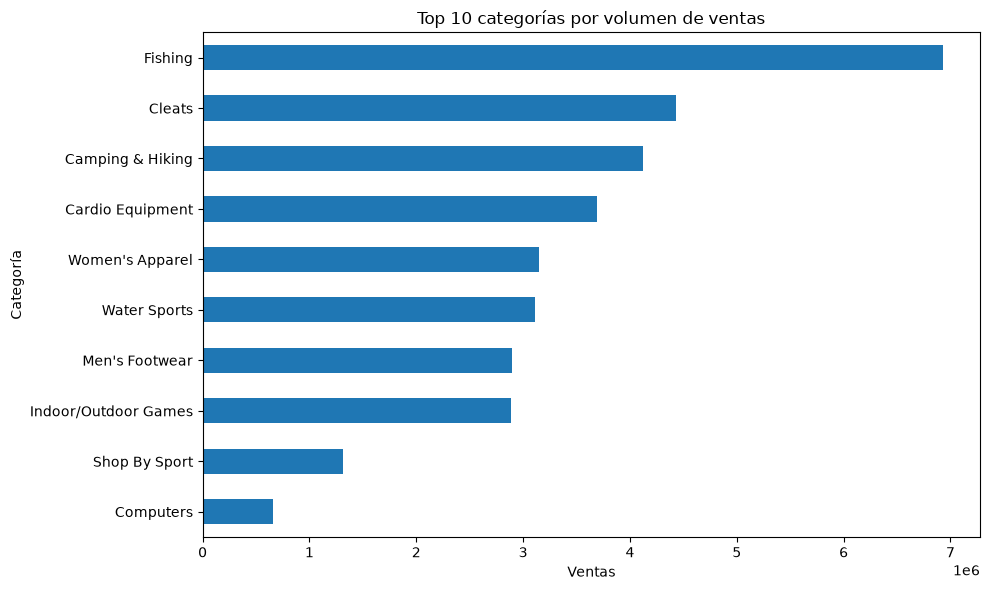

In [123]:
# Seleccionamos las 10 categorías con mayor volumen de ventas

top_10_categorias = ventas_categoria.head(10)

# Gráfico de ventas por categoría

plt.figure(figsize=(10, 6))

top_10_categorias.sort_values().plot(kind="barh")

plt.title("Top 10 categorías por volumen de ventas")
plt.xlabel("Ventas")
plt.ylabel("Categoría")



plt.tight_layout()
plt.show()

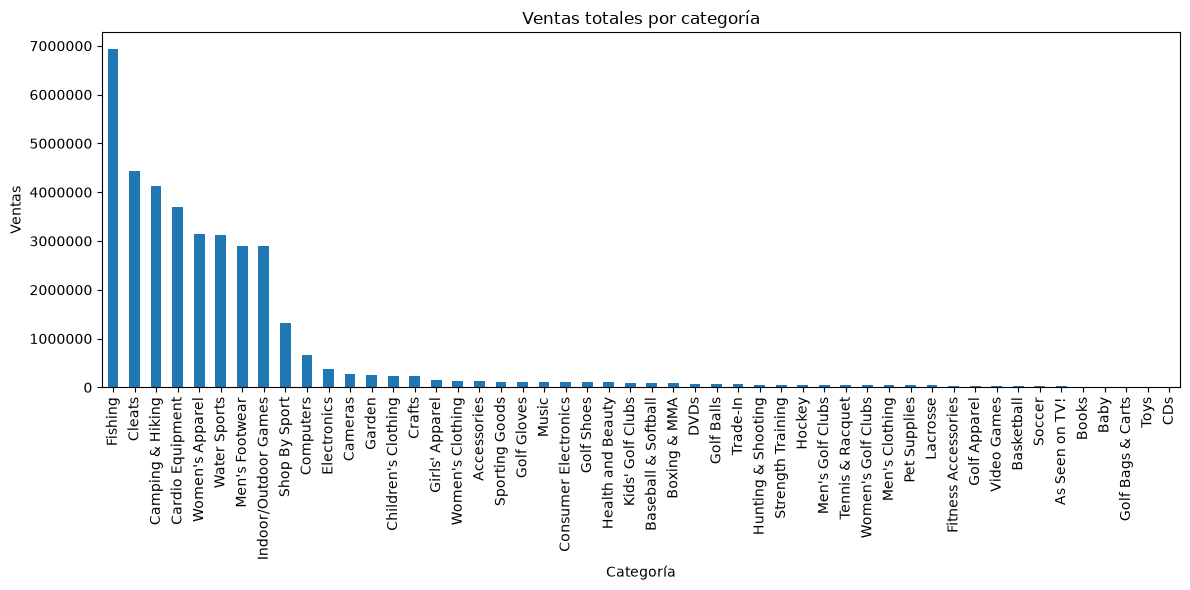

In [124]:
# Gráfico de ventas por categoría

plt.figure(figsize=(12, 6))

ventas_categoria.plot(kind="bar")

plt.title("Ventas totales por categoría")
plt.xlabel("Categoría")
plt.ylabel("Ventas")

plt.xticks(rotation=90)

plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

### Ventas por Mercado

Para completar el análisis de las ventas, se estudia su distribución entre los diferentes mercados en los que se realizan las operaciones. El objetivo es identificar qué mercados concentran un mayor volumen de ventas y comprobar si existen diferencias relevantes entre ellos.

In [125]:
# Ventas totales por mercado

ventas_mercado = (
    df.groupby("market", observed=True)["sales"]
    .sum()
    .sort_values(ascending=False)
)

print(ventas_mercado.round(0).map(lambda x: f"{x:,.0f}"))

market
Europe          10,872,397
LATAM           10,277,613
Pacific Asia     8,273,744
USCA             5,066,529
Africa           2,294,453
Name: sales, dtype: str


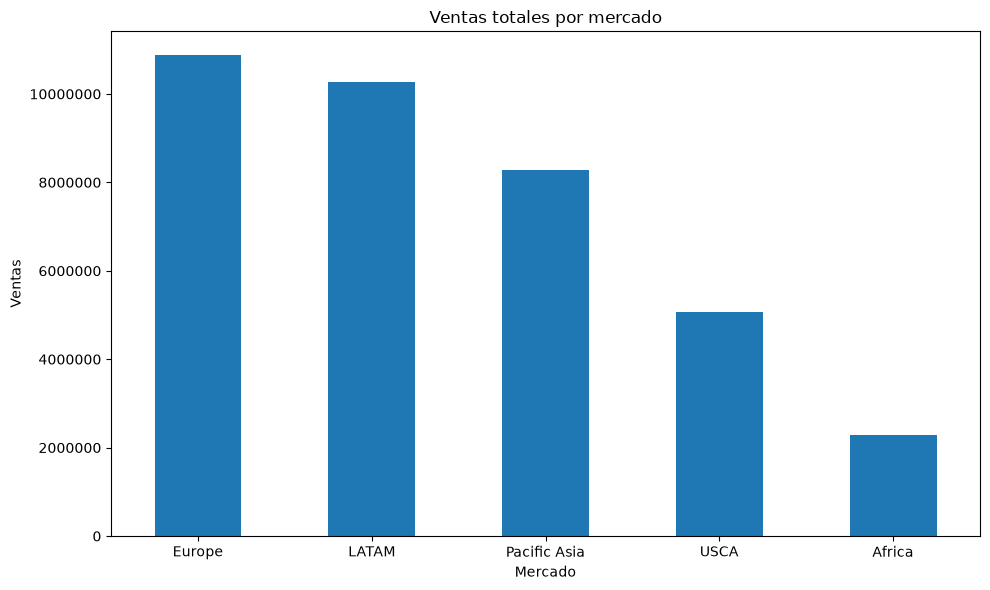

In [126]:
# Gráfico de ventas por mercado

plt.figure(figsize=(10, 6))

ventas_mercado.plot(kind="bar")

plt.title("Ventas totales por mercado")
plt.xlabel("Mercado")
plt.ylabel("Ventas")

plt.xticks(rotation=0)

plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

Se observan diferencias claras en las ventas según el mercado. Europa es el mercado con mayor volumen de ventas, seguido de Latino-América y Asia. En cambio, Estados Unidos/Canadá y, sobre todo, Africa presentan unas ventas bastante más bajas.

## 3.2 Análisis de rentabilidad
En este apartado se analiza la rentabilidad de las operaciones para conocer cómo se distribuye el beneficio y comprobar qué parte de las operaciones genera pérdidas. También se comparará el beneficio con el volumen de ventas para identificar si un mayor nivel de ventas se relaciona con una mayor rentabilidad.

### Ventas y beneficio
En este apartado se procede a analizar las ventas y el beneficio para saber cuanto se vende en total y cuanto beneficio se obtienen de esas ventas.

In [127]:
# Ventas y beneficio totales

ventas_totales = df["sales"].sum()
beneficio_total = df["benefit_per_order"].sum()

print(f"Ventas totales: {ventas_totales:,.0f}")
print(f"Beneficio total: {beneficio_total:,.0f}")

Ventas totales: 36,784,735
Beneficio total: 3,966,903


En total, las operaciones analizadas generan unas ventas de aproximadamente 36,8 millones y un beneficio de alrededor de 4 millones.


### Beneficio por categoría
¿Qué categorías concentran más beneficio?

In [128]:
# Beneficio total por categoría

beneficio_categoria = (
    df.groupby("category_name", observed=True)["benefit_per_order"]
    .sum()
    .sort_values(ascending=False)
)

print(beneficio_categoria.round(0).map(lambda x: f"{x:,.0f}"))

category_name
Fishing                 756,221
Cleats                  494,637
Camping & Hiking        427,456
Cardio Equipment        383,011
Women's Apparel         350,421
Water Sports            325,147
Indoor/Outdoor Games    318,451
Men's Footwear          311,903
Shop By Sport           129,814
Computers                69,657
Electronics              40,891
Garden                   33,443
Cameras                  30,290
Children's Clothing      27,178
Crafts                   25,531
Women's Clothing         19,103
Girls' Apparel           17,289
Accessories              16,644
Music                    14,436
Consumer Electronics     13,223
Golf Gloves              12,975
Baseball & Softball      12,762
Sporting Goods           12,519
Golf Shoes               12,406
Health and Beauty         9,494
Kids' Golf Clubs          9,046
Boxing & MMA              8,641
Golf Balls                8,343
Trade-In                  7,915
DVDs                      6,655
Hunting & Shooting        

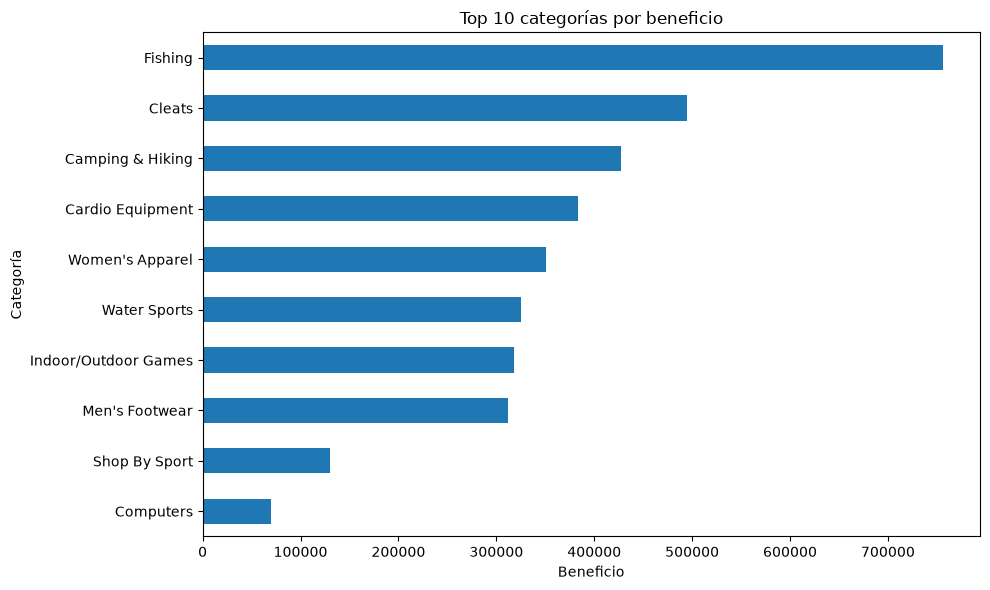

In [129]:
# Seleccionamos las 10 categorías con mayor beneficio

top_10_beneficio = beneficio_categoria.head(10)

# Gráfico de beneficio por categoría

plt.figure(figsize=(10, 6))

top_10_beneficio.sort_values().plot(kind="barh")

plt.title("Top 10 categorías por beneficio")
plt.xlabel("Beneficio")
plt.ylabel("Categoría")

plt.ticklabel_format(style="plain", axis="x")

plt.tight_layout()
plt.show()

Los resultados muestran que las categorías con mayores ventas son, en general, también las que generan un mayor beneficio. Fishing vuelve a destacar como la categoría con mayor beneficio, seguida de Cleats, Camping & Hiking y Cardio Equipment. Aunque existen operaciones con pérdidas, ninguna categoría presenta pérdidas de forma global al sumar el resultado de todas sus operaciones

### Relación entre ventas y rentabilidad 
¿Las categorías que más venden son también las más rentables?


In [130]:
# Ventas y beneficio total por categoría

ventas_beneficio_categoria = (
    df.groupby("category_name", observed=True)[["sales", "benefit_per_order"]]
    .sum()
    .sort_values("sales", ascending=False)
)

# Calculamos el margen de beneficio

ventas_beneficio_categoria["Margen (%)"] = (
    ventas_beneficio_categoria["benefit_per_order"]
    / ventas_beneficio_categoria["sales"]
    * 100
)

print(ventas_beneficio_categoria.round(2))

                           sales  benefit_per_order  Margen (%)
category_name                                                  
Fishing               6929653.69          756220.77       10.91
Cleats                4431942.78          494636.92       11.16
Camping & Hiking      4118425.57          427455.57       10.38
Cardio Equipment      3694843.20          383011.10       10.37
Women's Apparel       3147800.00          350421.03       11.13
Water Sports          3113844.68          325146.96       10.44
Men's Footwear        2891757.66          311902.82       10.79
Indoor/Outdoor Games  2888993.91          318451.43       11.02
Shop By Sport         1309522.04          129813.96        9.91
Computers              663000.00           69656.81       10.51
Electronics            371034.64           40891.38       11.02
Cameras                267607.69           30289.80       11.32
Garden                 257768.73           33443.01       12.97
Children's Clothing    232829.20        

Los resultados muestran que un mayor volumen de ventas no implica necesariamente una mayor rentabilidad. Las categorías con mayores ventas, como Fishing, Cleats, Camping & Hiking y Cardio Equipment, presentan márgenes cercanos al 10-11 %, mientras que algunas categorías con un volumen de ventas mucho menor alcanzan márgenes superiores. También se observa el caso de Strength Training, que presenta un margen muy reducido a pesar de generar ventas. Por tanto, no se observa una relación directa entre el volumen de ventas y el margen de beneficio.

### Operaciones con pérdidas

En este apartado se analizarán las operaciones que presentan un beneficio negativo para determinar cuántas operaciones generan pérdidas, qué porcentaje representan sobre el total y en qué categorías se concentran principalmente. El análisis de las relaciones entre las diferentes variables numéricas se realizará posteriormente en el apartado de correlaciones.

In [131]:
# Filtramos las operaciones con beneficio negativo

operaciones_perdidas = df[df["benefit_per_order"] < 0]

# Número de operaciones con pérdidas

num_perdidas = len(operaciones_perdidas)

# Porcentaje sobre el total de operaciones

porcentaje_perdidas = num_perdidas / len(df) * 100

print(f"Operaciones con pérdidas: {num_perdidas:,}")
print(f"Porcentaje sobre el total: {porcentaje_perdidas:.2f}%")

Operaciones con pérdidas: 33,784
Porcentaje sobre el total: 18.71%


Los resultados muestran que 33.784 operaciones presentan un beneficio negativo, lo que representa el 18,71 % del total de operaciones analizadas. Esto significa que aproximadamente una de cada cinco operaciones genera pérdidas, por lo que resulta relevante analizar dónde se concentran principalmente estas operaciones.

##### Operaciones con pérdidas por categoría
¿En qué categorías se concentran?

In [132]:
# Filtramos las operaciones con pérdidas

operaciones_perdidas = df[df["benefit_per_order"] < 0]

# Número de operaciones con pérdidas por categoría

perdidas_categoria = (
    operaciones_perdidas.groupby("category_name", observed=True)
    .size()
    .sort_values(ascending=False)
)

print(perdidas_categoria)

category_name
Cleats                  4590
Men's Footwear          4169
Women's Apparel         3923
Indoor/Outdoor Games    3617
Fishing                 3209
Water Sports            2924
Camping & Hiking        2590
Cardio Equipment        2332
Shop By Sport           2154
Electronics              562
Accessories              319
Golf Balls               263
Girls' Apparel           232
Video Games              181
Golf Gloves              180
Trade-In                 177
Children's Clothing      125
Golf Shoes               111
Hockey                   111
Cameras                  108
Women's Clothing         107
Baseball & Softball      106
Pet Supplies             104
DVDs                     102
Crafts                    96
Golf Apparel              88
Health and Beauty         85
Hunting & Shooting        85
Toys                      82
Garden                    82
Music                     80
Boxing & MMA              80
Consumer Electronics      79
Books                     78


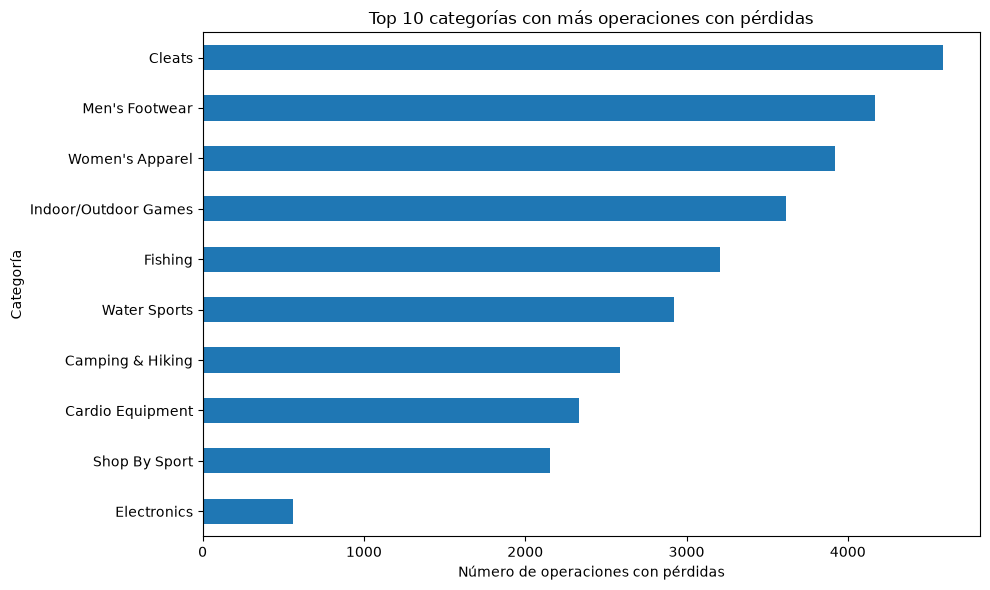

In [133]:
# Seleccionamos las 10 categorías con más operaciones con pérdidas

top_10_perdidas = perdidas_categoria.head(10)

# Gráfico de operaciones con pérdidas por categoría

plt.figure(figsize=(10, 6))

top_10_perdidas.sort_values().plot(kind="barh")

plt.title("Top 10 categorías con más operaciones con pérdidas")
plt.xlabel("Número de operaciones con pérdidas")
plt.ylabel("Categoría")

plt.tight_layout()
plt.show()

Las operaciones con pérdidas se concentran principalmente en las categorías con mayor volumen de actividad. Cleats presenta el mayor número de operaciones con pérdidas, con 4.590, seguida de Men's Footwear, Women's Apparel e Indoor/Outdoor Games. Estas categorías también se encuentran entre las que presentan mayores niveles de ventas y beneficio. Por tanto, el número de operaciones con pérdidas parece estar relacionado con el volumen de actividad de cada categoría

##### Importe de las pérdidas por categoría
Una vez identificadas las categorías que concentran un mayor número de operaciones con pérdidas, se analizará el importe total de las pérdidas acumuladas en cada categoría. De esta forma, se podrá determinar qué categorías tienen un mayor impacto económico negativo para la empresa.

In [134]:
# Importe total de las pérdidas por categoría

perdidas_importe_categoria = (
    operaciones_perdidas.groupby("category_name", observed=True)["benefit_per_order"]
    .sum()
    .sort_values()
)

print(perdidas_importe_categoria.round(0).map(lambda x: f"{x:,.0f}"))

category_name
Fishing                 -728,571
Cleats                  -452,594
Camping & Hiking        -443,082
Cardio Equipment        -402,647
Water Sports            -334,570
Women's Apparel         -323,773
Men's Footwear          -309,270
Indoor/Outdoor Games    -298,637
Shop By Sport           -144,311
Computers                -74,967
Electronics              -38,814
Cameras                  -27,395
Garden                   -24,512
Children's Clothing      -23,287
Crafts                   -21,769
Girls' Apparel           -15,068
Sporting Goods           -12,910
Accessories              -12,581
Golf Gloves              -12,454
Women's Clothing         -12,101
Health and Beauty        -11,939
Golf Shoes               -11,724
Kids' Golf Clubs         -11,093
Strength Training        -10,657
Music                     -9,830
Boxing & MMA              -9,785
Consumer Electronics      -9,621
DVDs                      -9,143
Baseball & Softball       -8,220
Golf Balls                -7,

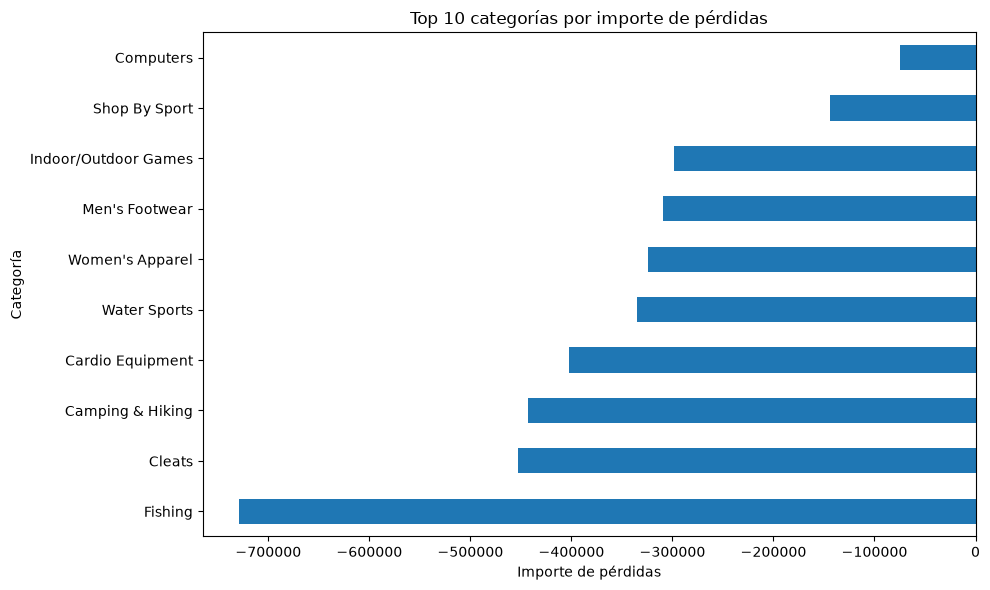

In [135]:
# Seleccionamos las 10 categorías con mayor importe de pérdidas

top_10_importe_perdidas = perdidas_importe_categoria.head(10)

# Gráfico del importe de pérdidas por categoría

plt.figure(figsize=(10, 6))

top_10_importe_perdidas.sort_values().plot(kind="barh")

plt.title("Top 10 categorías por importe de pérdidas")
plt.xlabel("Importe de pérdidas")
plt.ylabel("Categoría")

plt.ticklabel_format(style="plain", axis="x")

plt.tight_layout()
plt.show()

Las pérdidas acumuladas se concentran principalmente en las categorías con mayor volumen de actividad. Fishing presenta el mayor importe de pérdidas, con aproximadamente 728.571 €, seguida de Cleats, Camping & Hiking y Cardio Equipment. En conjunto, estas categorías concentran una parte importante del impacto económico negativo, por lo que deberían recibir especial atención en análisis posteriores. No obstante, este resultado únicamente muestra dónde se concentra el impacto de las pérdidas, por lo que será necesario analizar posteriormente qué factores pueden estar relacionados con su aparición.

## 3.3 Analisis logístico
En este apartado se analizará el funcionamiento de los envíos para identificar posibles problemas en los tiempos de entrega y determinar si existen diferencias relevantes entre los distintos mercados o categorías. El objetivo es detectar posibles áreas de mejora en el proceso logístico que puedan afectar al rendimiento de la empresa.

##### Tiempo real vs. tiempo programado de envío
En primer lugar, se comparará el tiempo real de envío con el tiempo programado para comprobar si los pedidos se entregan dentro del plazo previsto y detectar posibles retrasos.

In [136]:
# Diferencia entre el tiempo real y el tiempo programado de envío

df["diferencia_envio"] = (
    df["days_for_shipping_real"]
    - df["days_for_shipment_scheduled"]
)

print(df["diferencia_envio"].value_counts().sort_index())


print(f"Tiempo real medio: {df['days_for_shipping_real'].mean():.2f} días")
print(f"Tiempo programado medio: {df['days_for_shipment_scheduled'].mean():.2f} días")
print(f"Diferencia media: {df['diferencia_envio'].mean():.2f} días")



diferencia_envio
-2    21666
-1    21700
 0    33753
 1    60647
 2    28718
 3     7052
 4     6983
Name: count, dtype: int64
Tiempo real medio: 3.50 días
Tiempo programado medio: 2.93 días
Diferencia media: 0.57 días


Los resultados muestran que el tiempo real medio de envío es de 3,50 días, frente a los 2,93 días programados, lo que supone un retraso medio de 0,57 días. De las 180.519 operaciones analizadas, 103.400 presentan algún retraso, frente a 33.753 que se realizan exactamente dentro del plazo previsto y 43.366 que se entregan antes de lo programado. Por tanto, las operaciones retrasadas representan una parte importante de los pedidos y superan ampliamente a las operaciones entregadas dentro del plazo, siendo el retraso de un día el más frecuente, con 60.647 operaciones. Esto apunta a un posible problema en el cumplimiento de los plazos de entrega que deberá analizarse por mercado y categoría.

##### Retrasos por mercado
A continuación, se analizarán las operaciones retrasadas según el mercado al que pertenecen, con el objetivo de identificar si los retrasos se concentran en determinados mercados y detectar posibles diferencias en el rendimiento logístico entre ellos.

In [137]:
# Filtramos las operaciones retrasadas

operaciones_retrasadas = df[df["diferencia_envio"] > 0]

# Número de operaciones retrasadas por mercado

retrasos_mercado = (
    operaciones_retrasadas.groupby("market", observed=True)
    .size()
    .sort_values(ascending=False)
)

print(retrasos_mercado)

market
LATAM           29420
Europe          28989
Pacific Asia    23649
USCA            14744
Africa           6598
dtype: int64


In [138]:
# Porcentaje de operaciones retrasadas por mercado

total_mercado = (
    df.groupby("market", observed=True)
    .size()
)

porcentaje_retrasos_mercado = (
    retrasos_mercado / total_mercado * 100
).sort_values(ascending=False)

print(porcentaje_retrasos_mercado.round(2))

market
Europe          57.69
Pacific Asia    57.32
USCA            57.15
LATAM           57.02
Africa          56.81
dtype: float64


Los resultados muestran que los retrasos presentan una distribución muy similar entre los distintos mercados. Europe registra el porcentaje más elevado, con un 57,69 %, mientras que Africa presenta el menor, con un 56,81 %. La diferencia entre ambos mercados es inferior a un punto porcentual, por lo que no se observan diferencias relevantes en el comportamiento logístico según el mercado. Esto indica que el problema de los retrasos parece ser generalizado y no estar concentrado en una zona geográfica concreta.

##### Retrasos por categoría
A continuación, se analizarán las operaciones retrasadas según la categoría de producto, con el objetivo de identificar si los retrasos se concentran en determinadas categorías y detectar posibles diferencias en el rendimiento logístico según el tipo de producto.

In [139]:
# Número de operaciones retrasadas por categoría

retrasos_categoria = (
    operaciones_retrasadas.groupby("category_name", observed=True)
    .size()
    .sort_values(ascending=False)
)

print(retrasos_categoria)

category_name
Cleats                  14076
Men's Footwear          12664
Women's Apparel         12017
Indoor/Outdoor Games    11043
Fishing                  9930
Water Sports             8891
Camping & Hiking         7812
Cardio Equipment         7110
Shop By Sport            6328
Electronics              1847
Accessories              1053
Golf Balls                847
Girls' Apparel            704
Golf Gloves               625
Trade-In                  569
Video Games               472
Women's Clothing          381
Children's Clothing       369
Cameras                   367
Baseball & Softball       357
Hockey                    342
Toys                      309
Golf Shoes                303
Pet Supplies              302
Crafts                    288
Garden                    276
DVDs                      272
Music                     258
Hunting & Shooting        257
Consumer Electronics      255
Boxing & MMA              251
Golf Apparel              235
Books                     

In [140]:
# Total de operaciones por categoría

total_categoria = (
    df.groupby("category_name", observed=True)
    .size()
)

# Porcentaje de operaciones retrasadas por categoría

porcentaje_retrasos_categoria = (
    retrasos_categoria / total_categoria * 100
).sort_values(ascending=False)

print(porcentaje_retrasos_categoria.round(2))

category_name
Golf Bags & Carts       68.85
Lacrosse                62.10
Cameras                 61.99
Pet Supplies            61.38
Sporting Goods          59.94
Basketball              59.70
Fitness Accessories     59.55
Crafts                  59.50
Strength Training       59.46
Music                   59.45
Boxing & MMA            59.34
Consumer Electronics    59.16
Accessories             59.16
As Seen on TV!          58.82
Girls' Apparel          58.62
Women's Clothing        58.62
Health and Beauty       58.56
Electronics             58.52
Trade-In                58.42
Toys                    58.41
Golf Gloves             58.41
Hunting & Shooting      58.41
Kids' Golf Clubs        58.33
Tennis & Racquet        57.93
Golf Shoes              57.82
Shop By Sport           57.61
Books                   57.53
Golf Balls              57.42
Cleats                  57.33
Fishing                 57.32
Indoor/Outdoor Games    57.22
Water Sports            57.21
Women's Apparel         57

Los resultados muestran que el porcentaje de operaciones retrasadas es elevado en la mayoría de las categorías, aunque existen algunas diferencias entre ellas. Golf Bags & Carts presenta el porcentaje más alto, con un 68,85 %, seguida de Lacrosse, Cameras y Pet Supplies, todas por encima del 60 %. En cambio, Men's Golf Clubs presenta el porcentaje más bajo, con un 49,82 %. A pesar de estas diferencias, la mayoría de las categorías se sitúan en torno al 55-60 %, por lo que los retrasos parecen ser un problema generalizado y no exclusivo de determinadas categorías.

##### Retrasos según el tipo de envío

Por último, se analizarán las operaciones retrasadas según el tipo de envío utilizado, con el objetivo de comprobar si existen diferencias en el porcentaje de retrasos entre las distintas modalidades y determinar si alguna presenta un comportamiento logístico menos eficiente.

In [141]:
# Número de operaciones retrasadas por tipo de envío

retrasos_tipo_envio = (
    operaciones_retrasadas.groupby("shipping_mode", observed=True)
    .size()
    .sort_values(ascending=False)
)

print(retrasos_tipo_envio)

shipping_mode
Standard Class    42851
Second Class      28078
First Class       27814
Same Day           4657
dtype: int64


In [142]:
# Total de operaciones por tipo de envío

total_tipo_envio = (
    df.groupby("shipping_mode", observed=True)
    .size()
)

# Porcentaje de operaciones retrasadas por tipo de envío

porcentaje_retrasos_tipo_envio = (
    retrasos_tipo_envio / total_tipo_envio * 100
).sort_values(ascending=False)

print(porcentaje_retrasos_tipo_envio.round(2))

shipping_mode
First Class       100.00
Second Class       79.73
Same Day           47.83
Standard Class     39.77
dtype: float64


Los resultados muestran diferencias importantes en el porcentaje de retrasos según el tipo de envío. First Class presenta retrasos en el 100 % de las operaciones, mientras que Second Class alcanza un 79,73 %. En cambio, Same Day y Standard Class presentan porcentajes inferiores, con un 47,83 % y un 39,77 %, respectivamente. Por tanto, el tipo de envío presenta diferencias claras en su comportamiento logístico y First Class y Second Class destacan como las modalidades con mayor proporción de retrasos, por lo que deberían ser objeto de una revisión posterior.

##### Conclusión del análisis logístico

El análisis muestra que los retrasos son frecuentes y están presentes de forma similar en los distintos mercados y categorías. Sin embargo, se observan diferencias importantes según el tipo de envío, destacando First Class y Second Class por sus elevados porcentajes de retrasos. Por tanto, el tipo de envío aparece como el aspecto más relevante a revisar dentro del análisis logístico

## 3.4 Análisis de relaciones entre variables
En este apartado se analizarán las relaciones entre las principales variables del conjunto de datos con el objetivo de identificar qué factores pueden estar relacionados con los problemas detectados en el análisis anterior, especialmente las operaciones con pérdidas y los retrasos en los envíos.

### Factores relacionados con las operaciones con pérdidas
En este apartado se analizarán las características de las operaciones con pérdidas y se compararán con aquellas que no presentan pérdidas. El objetivo es identificar qué variables pueden estar relacionadas con un resultado negativo y determinar qué factores podrían contribuir a la aparición de estas operaciones

In [143]:
# Creamos una variable binaria para identificar si cada operación genera pérdidas
# 1 = operación con pérdidas | 0 = operación sin pérdidas

df["operacion_con_perdida"] = (
    df["benefit_per_order"] < 0
).astype(int)

print(df["operacion_con_perdida"].value_counts())

operacion_con_perdida
0    146735
1     33784
Name: count, dtype: int64


In [144]:
# Comparamos las principales variables numéricas entre operaciones con y sin pérdidas

variables_numericas = [
    "sales",
    "order_item_discount",
    "order_item_quantity",
    "order_item_product_price",
    "order_item_total",
    "days_for_shipping_real",
    "days_for_shipment_scheduled"
]

# Agrupamos las operaciones según si generan pérdidas o no y calculamos la media

comparacion_perdidas = (
    df.groupby("operacion_con_perdida")[variables_numericas]
    .mean()
    .round(2)
)

print(comparacion_perdidas)

                        sales  order_item_discount  order_item_quantity  \
operacion_con_perdida                                                     
0                      203.87                20.65                 2.13   
1                      203.36                20.73                 2.13   

                       order_item_product_price  order_item_total  \
operacion_con_perdida                                               
0                                        141.32            183.22   
1                                        140.84            182.63   

                       days_for_shipping_real  days_for_shipment_scheduled  
operacion_con_perdida                                                       
0                                        3.49                         2.93  
1                                        3.51                         2.94  


Los resultados muestran que las características medias de las operaciones con pérdidas y sin pérdidas son muy similares. No se observan diferencias relevantes en las ventas, los descuentos, la cantidad de productos, el precio o los tiempos de envío. Por tanto, estas variables no parecen explicar por sí solas la aparición de operaciones con pérdidas. 

##### Distribución de las variables en las operaciones con pérdidas

Dado que la comparación de las medias no ha mostrado diferencias relevantes entre las operaciones con pérdidas y sin pérdidas, se analizará la distribución de las principales variables para comprobar si existen patrones que no puedan observarse únicamente mediante sus valores medios. Este análisis permitirá identificar posibles concentraciones de valores o diferencias en el comportamiento de las operaciones que puedan ayudar a explicar la aparición de pérdidas. Para buscar posibles causas será necesario continuar analizando otras características de las operaciones, especialmente las variables categóricas.

##### variables categóricas

In [145]:
# Identificamos las variables categóricas del conjunto de datos

variables_categoricas = df.select_dtypes(include="object").columns.tolist()

print(variables_categoricas)

['type', 'category_name', 'customer_city', 'customer_country', 'customer_email', 'customer_fname', 'customer_lname', 'customer_password', 'customer_state', 'customer_street', 'department_name', 'order_city', 'order_country', 'order_state', 'product_image', 'product_name']


C:\Users\acer\AppData\Local\Temp\ipykernel_21156\857101454.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  variables_categoricas = df.select_dtypes(include="object").columns.tolist()


In [146]:
# Calculamos el porcentaje de operaciones con pérdidas por categoría de producto

perdidas_categoria = (
    df.groupby("category_name")["operacion_con_perdida"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .round(2)
)

print(perdidas_categoria)

category_name
Men's Clothing          24.04
Health and Beauty       23.48
Video Games             21.60
Golf Shoes              21.18
Pet Supplies            21.14
DVDs                    21.12
As Seen on TV!          20.59
Kids' Golf Clubs        20.05
Golf Apparel            19.95
Crafts                  19.83
Shop By Sport           19.61
Tennis & Racquet        19.51
Hunting & Shooting      19.32
Girls' Apparel          19.32
Books                   19.26
Children's Clothing     19.17
Boxing & MMA            18.91
Camping & Hiking        18.87
Water Sports            18.82
Indoor/Outdoor Games    18.74
Men's Footwear          18.74
Cleats                  18.70
Cardio Equipment        18.68
Women's Apparel         18.65
Fishing                 18.52
Music                   18.43
Consumer Electronics    18.33
Cameras                 18.24
Trade-In                18.17
Hockey                  18.08
Lacrosse                18.08
Accessories             17.92
Golf Balls              17

Al analizar las operaciones con pérdidas según la categoría de producto, se observan diferencias en la proporción de operaciones negativas entre las distintas categorías. Algunas presentan porcentajes de pérdidas superiores a la media general, mientras que otras muestran valores inferiores. Este resultado sugiere que la categoría de producto podría estar relacionada con la aparición de operaciones con pérdidas. No obstante, es necesario considerar también el número de operaciones de cada categoría antes de determinar si estas diferencias representan un patrón relevante.

In [147]:
# Comparamos la tasa de operaciones con pérdidas y el número de operaciones de cada categoría

analisis_categoria = (
    df.groupby("category_name")["operacion_con_perdida"]
    .agg(["mean", "count"])
    .rename(columns={
        "mean": "Porcentaje pérdidas",
        "count": "Número operaciones"
    })
)

analisis_categoria["Porcentaje pérdidas"] = (
    analisis_categoria["Porcentaje pérdidas"] * 100
).round(2)

analisis_categoria = analisis_categoria.sort_values(
    "Porcentaje pérdidas",
    ascending=False
)

print(analisis_categoria)

                      Porcentaje pérdidas  Número operaciones
category_name                                                
Men's Clothing                      24.04                 208
Health and Beauty                   23.48                 362
Video Games                         21.60                 838
Golf Shoes                          21.18                 524
Pet Supplies                        21.14                 492
DVDs                                21.12                 483
As Seen on TV!                      20.59                  68
Kids' Golf Clubs                    20.05                 384
Golf Apparel                        19.95                 441
Crafts                              19.83                 484
Shop By Sport                       19.61               10984
Tennis & Racquet                    19.51                 328
Girls' Apparel                      19.32                1201
Hunting & Shooting                  19.32                 440
Books   

Al considerar conjuntamente el porcentaje de operaciones con pérdidas y el volumen de operaciones de cada categoría, no se observa un patrón suficientemente claro que permita relacionar de forma directa la categoría del producto con la aparición de pérdidas. Las categorías con porcentajes más elevados presentan, en muchos casos, un número reducido de operaciones, mientras que las categorías con mayor volumen muestran tasas de pérdidas muy similares a la media general del conjunto de datos, situada en torno al 18,7 %. Por tanto, la categoría de producto no parece ser, por sí sola, un factor determinante para explicar la aparición de operaciones con pérdidas.

In [148]:
# Analizamos la proporción de operaciones con pérdidas para todas las variables categóricas

variables_categoricas = [
    "delivery_status",
    "customer_segment",
    "market",
    "order_region",
    "order_status",
    "shipping_mode"
]

for variable in variables_categoricas:

    print(f"\n{'=' * 60}")
    print(variable)
    print('=' * 60)

    resultado = (
        df.groupby(variable, observed=True)["operacion_con_perdida"]
        .agg(["mean", "count"])
    )

    resultado["Porcentaje pérdidas"] = (
        resultado["mean"] * 100
    ).round(2)

    resultado = resultado.rename(
        columns={"count": "Número operaciones"}
    )

    print(
        resultado[
            ["Porcentaje pérdidas", "Número operaciones"]
        ].sort_values(
            "Porcentaje pérdidas",
            ascending=False
        )
    )


delivery_status
                   Porcentaje pérdidas  Número operaciones
delivery_status                                           
Shipping canceled                19.20                7754
Late delivery                    18.74               98977
Advance shipping                 18.69               41592
Shipping on time                 18.54               32196

customer_segment
                  Porcentaje pérdidas  Número operaciones
customer_segment                                         
Home Office                     18.85               32226
Corporate                       18.82               54789
Consumer                        18.60               93504

market
              Porcentaje pérdidas  Número operaciones
market                                               
Pacific Asia                18.92               41260
Europe                      18.75               50252
USCA                        18.65               25799
Africa                      18.58          

In [149]:
# Analizamos con más detalle las diferencias de pérdidas entre las regiones

analisis_region = (
    df.groupby("order_region", observed=True)["operacion_con_perdida"]
    .agg(["mean", "count", "sum"])
    .rename(columns={
        "mean": "Porcentaje pérdidas",
        "count": "Número operaciones",
        "sum": "Operaciones con pérdidas"
    })
)

analisis_region["Porcentaje pérdidas"] = (
    analisis_region["Porcentaje pérdidas"] * 100
).round(2)

analisis_region = analisis_region.sort_values(
    "Porcentaje pérdidas",
    ascending=False
)

print(analisis_region)

                 Porcentaje pérdidas  Número operaciones  \
order_region                                               
Central Africa                 19.92                1677   
Eastern Europe                 19.72                3920   
Eastern Asia                   19.19                7280   
Oceania                        19.16               10148   
North Africa                   19.09                3232   
South Asia                     19.00                7731   
West Africa                    18.91                3696   
West of USA                    18.90                7993   
US Center                      18.87                5887   
Western Europe                 18.83               27109   
Caribbean                      18.83                8318   
Southeast Asia                 18.77                9539   
East of USA                    18.60                6915   
Central America                18.59               28341   
West Asia                      18.54    

El análisis de las variables categóricas muestra que la mayoría presenta porcentajes de operaciones con pérdidas muy similares entre sus diferentes categorías. customer_segment, market, order_status y shipping_mode presentan diferencias reducidas respecto a la tasa media de pérdidas, situada en torno al 18,7 %.

order_region presenta una mayor variabilidad, con porcentajes que oscilan entre el 16,16 % y el 19,92 %. Sin embargo, estas diferencias no son suficientemente elevadas como para afirmar que la región sea un factor determinante de las pérdidas. Además, algunas de las regiones con mayores porcentajes cuentan con un número reducido de operaciones, por lo que sus resultados deben interpretarse con cautela.

Por otro lado, al analizar el número absoluto de operaciones con pérdidas, las regiones con mayor volumen de operaciones concentran también un mayor número de pérdidas. Esto refuerza la idea observada anteriormente de que el volumen de actividad tiene una mayor relación con el número de operaciones con pérdidas que las características categóricas analizadas.

En conjunto, las variables categóricas estudiadas no muestran una relación suficientemente clara con la aparición de pérdidas. Por tanto, no se identifican a partir de este análisis factores categóricos que permitan explicar por sí solos el origen de las operaciones con pérdidas.

In [150]:
# Analizamos la distribución del beneficio entre las operaciones que generan pérdidas

perdidas = df[df["operacion_con_perdida"] == 1]

print(perdidas["benefit_per_order"].describe().round(2))

count    33784.00
mean      -114.95
std        160.28
min      -4274.98
25%       -149.39
50%        -57.37
75%        -20.57
max         -0.13
Name: benefit_per_order, dtype: float64


In [151]:
# Calculamos el impacto económico total de las operaciones con pérdidas

perdida_total = perdidas["benefit_per_order"].sum()
perdida_media = perdidas["benefit_per_order"].mean()
perdida_mediana = perdidas["benefit_per_order"].median()

print(f"Pérdida total: {perdida_total:,.2f}")
print(f"Pérdida media por operación: {perdida_media:,.2f}")
print(f"Pérdida mediana por operación: {perdida_mediana:,.2f}")

Pérdida total: -3,883,547.35
Pérdida media por operación: -114.95
Pérdida mediana por operación: -57.37


In [152]:
# Analizamos cuánto dinero se pierde en cada categoría de producto

perdidas_categoria = (
    perdidas.groupby("category_name")["benefit_per_order"]
    .agg(["sum", "mean", "count"])
    .rename(columns={
        "sum": "Pérdida total",
        "mean": "Pérdida media",
        "count": "Operaciones con pérdidas"
    })
    .sort_values("Pérdida total")
)

print(perdidas_categoria.round(2))

                      Pérdida total  Pérdida media  Operaciones con pérdidas
category_name                                                               
Fishing                  -728570.95        -227.04                      3209
Cleats                   -452594.21         -98.60                      4590
Camping & Hiking         -443082.23        -171.07                      2590
Cardio Equipment         -402647.26        -172.66                      2332
Water Sports             -334569.63        -114.42                      2924
Women's Apparel          -323772.87         -82.53                      3923
Men's Footwear           -309269.70         -74.18                      4169
Indoor/Outdoor Games     -298637.48         -82.56                      3617
Shop By Sport            -144310.56         -67.00                      2154
Computers                 -74967.13       -1026.95                        73
Electronics               -38814.32         -69.06                       562

Los resultados muestran que el impacto económico de las operaciones con pérdidas no se distribuye de forma uniforme entre las categorías de producto. Fishing concentra la mayor pérdida total, con aproximadamente 728.571 €, seguida de Cleats, Camping & Hiking y Cardio Equipment. Estas categorías presentan además un número elevado de operaciones con pérdidas, lo que contribuye a explicar su mayor impacto acumulado.

Sin embargo, el número de operaciones con pérdidas no determina por sí solo el impacto económico. Por ejemplo, Cleats registra 4.590 operaciones con pérdidas, frente a las 3.209 de Fishing, pero la pérdida total de Fishing es considerablemente mayor. Esto se debe a que la pérdida media por operación también es superior en Fishing (-227,04 € frente a -98,60 €).

También destaca Computers, que presenta únicamente 73 operaciones con pérdidas, pero una pérdida media de 1.026,95 € por operación. Este resultado indica que algunas categorías pueden generar un impacto económico elevado aunque el número de operaciones afectadas sea reducido.

Por tanto, el análisis muestra que para determinar dónde se concentra el problema de las pérdidas no es suficiente con analizar cuántas operaciones presentan un resultado negativo. También es necesario considerar el importe de las pérdidas generadas en cada operación. Las categorías con mayor impacto económico deberían ser objeto de un análisis más detallado para identificar qué características de sus operaciones pueden estar relacionadas con estas pérdidas

In [153]:
# Analizamos cuánto dinero se pierde en cada producto

perdidas_producto = (
    perdidas.groupby("product_name")["benefit_per_order"]
    .agg(["sum", "mean", "count"])
    .rename(columns={
        "sum": "Pérdida total",
        "mean": "Pérdida media",
        "count": "Operaciones con pérdidas"
    })
    .sort_values("Pérdida total")
)

print(perdidas_producto.head(20).round(2))

                                               Pérdida total  Pérdida media  \
product_name                                                                  
Field & Stream Sportsman 16 Gun Fire Safe         -728570.95        -227.04   
Perfect Fitness Perfect Rip Deck                  -450978.29         -98.40   
Diamondback Women's Serene Classic Comfort Bi     -443082.23        -171.07   
Nike Men's Free 5.0+ Running Shoe                 -400015.04        -176.14   
Pelican Sunstream 100 Kayak                       -332804.25        -114.13   
Nike Men's Dri-FIT Victory Golf Polo              -323772.87         -82.53   
Nike Men's CJ Elite 2 TD Football Cleat           -309269.70         -74.18   
O'Brien Men's Neoprene Life Vest                  -298637.48         -82.56   
Under Armour Girls' Toddler Spine Surge Runni     -139661.49         -66.98   
Dell Laptop                                        -74967.13       -1026.95   
Web Camera                                         -

El análisis a nivel de producto permite observar que las pérdidas se encuentran especialmente concentradas en determinados productos. El producto Field & Stream Sportsman 16 Gun Fire Safe presenta la mayor pérdida acumulada, con 728.570,95 €, seguido de Perfect Fitness Perfect Rip Deck, con 450.978,29 €, y Diamondback Women's Serene Classic Comfort Bi..., con 443.082,23 €.

Estos resultados muestran nuevamente que el número de operaciones con pérdidas no explica por sí solo el impacto económico. Por ejemplo, Perfect Fitness Perfect Rip Deck registra 4.583 operaciones con pérdidas y una pérdida media de 98,40 €, mientras que Dell Laptop presenta únicamente 73 operaciones con pérdidas, pero una pérdida media de 1.026,95 € por operación.

Por tanto, el problema de las pérdidas parece estar concentrado en determinados productos y no distribuido de manera uniforme entre todo el catálogo. Algunos productos generan un elevado número de operaciones con pérdidas, mientras que otros presentan pocas operaciones afectadas pero pérdidas de mayor importe por operación.

Este resultado permite identificar los productos con mayor impacto económico, aunque todavía no permite determinar qué características de estas operaciones están provocando las pérdidas. Para profundizar en el análisis será necesario estudiar las variables asociadas a estos productos y comprobar si existen patrones comunes en aspectos como los descuentos, precios, cantidades o condiciones de envío.

In [154]:
# Comparamos el descuento medio de las operaciones con pérdidas según el producto

productos_mas_perdidas = perdidas_producto.head(10).index

analisis_descuento_producto = (
    perdidas[perdidas["product_name"].isin(productos_mas_perdidas)]
    .groupby("product_name")["order_item_discount"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print(analisis_descuento_producto)

product_name
Dell Laptop                                      147.43
Field & Stream Sportsman 16 Gun Fire Safe         41.20
Diamondback Women's Serene Classic Comfort Bi     30.39
Nike Men's Free 5.0+ Running Shoe                 30.27
Pelican Sunstream 100 Kayak                       20.14
Perfect Fitness Perfect Rip Deck                  18.23
O'Brien Men's Neoprene Life Vest                  15.41
Nike Men's Dri-FIT Victory Golf Polo              15.39
Nike Men's CJ Elite 2 TD Football Cleat           13.15
Under Armour Girls' Toddler Spine Surge Runni     12.38
Name: order_item_discount, dtype: float64


In [155]:
# Comparamos el descuento medio entre operaciones con y sin pérdidas en los productos más afectados

productos_mas_perdidas = perdidas_producto.head(10).index

comparacion_descuento = (
    df[df["product_name"].isin(productos_mas_perdidas)]
    .groupby(["product_name", "operacion_con_perdida"])["order_item_discount"]
    .mean()
    .unstack()
    .round(2)
)

comparacion_descuento.columns = ["Sin pérdidas", "Con pérdidas"]

print(comparacion_descuento)

                                               Sin pérdidas  Con pérdidas
product_name                                                             
Dell Laptop                                          154.04        147.43
Diamondback Women's Serene Classic Comfort Bi         30.43         30.39
Field & Stream Sportsman 16 Gun Fire Safe             40.42         41.20
Nike Men's CJ Elite 2 TD Football Cleat               13.19         13.15
Nike Men's Dri-FIT Victory Golf Polo                  15.12         15.39
Nike Men's Free 5.0+ Running Shoe                     30.63         30.27
O'Brien Men's Neoprene Life Vest                      15.10         15.41
Pelican Sunstream 100 Kayak                           20.31         20.14
Perfect Fitness Perfect Rip Deck                      18.28         18.23
Under Armour Girls' Toddler Spine Surge Runni         12.01         12.38


Para comprobar si los descuentos pueden estar relacionados con las pérdidas, se comparó el descuento medio de las operaciones con y sin pérdidas dentro de los productos con mayor impacto económico. Los resultados muestran que las diferencias son muy reducidas en prácticamente todos los productos analizados.

Por ejemplo, en Dell Laptop el descuento medio es de 154,04 en las operaciones sin pérdidas y de 147,43 en las operaciones con pérdidas. De forma similar, en Perfect Fitness Perfect Rip Deck los valores son 18,28 y 18,23, respectivamente. Por tanto, no se observa un incremento claro del descuento en las operaciones que generan pérdidas.

En consecuencia, el descuento no parece ser un factor suficiente para explicar la aparición de operaciones con pérdidas en los productos analizados. Aunque pueda influir en determinadas operaciones, los resultados obtenidos no muestran una relación clara entre un mayor descuento y la generación de pérdidas.

In [156]:
# Comparamos el precio medio entre operaciones con y sin pérdidas en los productos más afectados

comparacion_precio = (
    df[df["product_name"].isin(productos_mas_perdidas)]
    .groupby(["product_name", "operacion_con_perdida"])["order_item_product_price"]
    .mean()
    .unstack()
    .round(2)
)

comparacion_precio.columns = ["Sin pérdidas", "Con pérdidas"]

print(comparacion_precio)

                                               Sin pérdidas  Con pérdidas
product_name                                                             
Dell Laptop                                         1500.00       1500.00
Diamondback Women's Serene Classic Comfort Bi        299.98        299.98
Field & Stream Sportsman 16 Gun Fire Safe            399.98        399.98
Nike Men's CJ Elite 2 TD Football Cleat              129.99        129.99
Nike Men's Dri-FIT Victory Golf Polo                  50.00         50.00
Nike Men's Free 5.0+ Running Shoe                     99.99         99.99
O'Brien Men's Neoprene Life Vest                      49.98         49.98
Pelican Sunstream 100 Kayak                          199.99        199.99
Perfect Fitness Perfect Rip Deck                      59.99         59.99
Under Armour Girls' Toddler Spine Surge Runni         39.99         39.99


También se analizó el precio del producto para comprobar si podía estar relacionado con la aparición de pérdidas. Para ello, se comparó el precio medio entre las operaciones con y sin pérdidas dentro de los productos con mayor impacto económico.

Los resultados muestran que el precio es exactamente el mismo en ambos grupos para los productos analizados. Por ejemplo, Dell Laptop presenta un precio medio de 1.500 € tanto en las operaciones con pérdidas como en las que no presentan pérdidas, mientras que Nike Men's Free 5.0+ Running Shoe mantiene un precio de 99,99 € en ambos casos.

Por tanto, el precio del producto no parece explicar por sí mismo la aparición de pérdidas. Esto indica que las diferencias entre operaciones con y sin pérdidas deben buscarse en otras características de la operación.

In [157]:
# Calculamos el coste estimado de cada operación a partir de las ventas y el beneficio

df["coste_estimado"] = df["sales"] - df["benefit_per_order"]

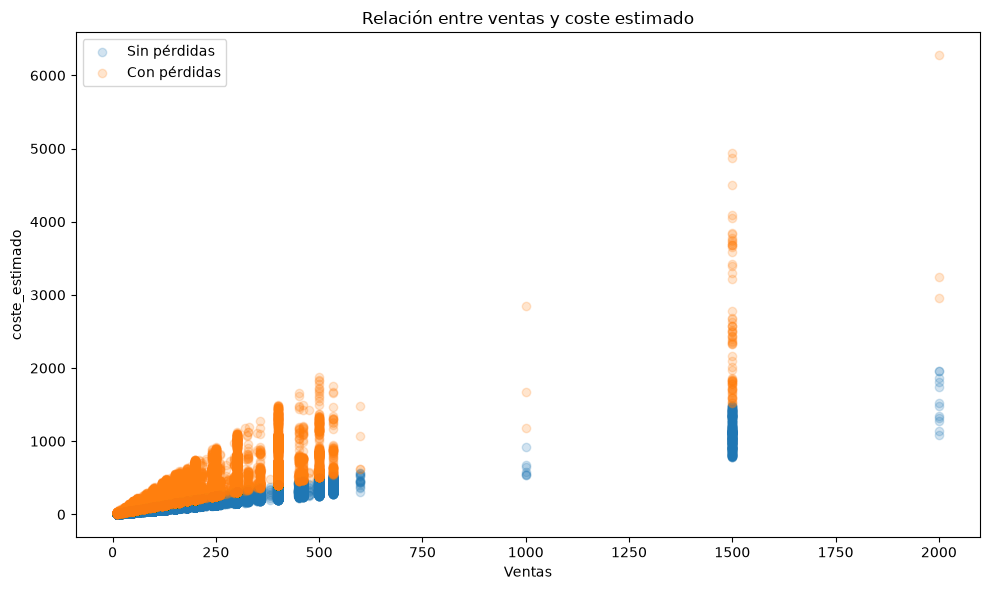

In [158]:
# Analizamos si las operaciones con pérdidas presentan costes elevados respecto a sus ventas

plt.figure(figsize=(10, 6))

plt.scatter(
    df[df["operacion_con_perdida"] == 0]["sales"],
    df[df["operacion_con_perdida"] == 0]["coste_estimado"],
    alpha=0.2,
    label="Sin pérdidas"
)

plt.scatter(
    df[df["operacion_con_perdida"] == 1]["sales"],
    df[df["operacion_con_perdida"] == 1]["coste_estimado"],
    alpha=0.2,
    label="Con pérdidas"
)

plt.title("Relación entre ventas y coste estimado")
plt.xlabel("Ventas")
plt.ylabel("coste_estimado")
plt.legend()

plt.tight_layout()
plt.show()

In [159]:
# Comparamos el porcentaje de coste sobre las ventas entre operaciones con y sin pérdidas

df["porcentaje_coste_sobre_ventas"] = (
    df["coste_estimado"] / df["sales"] * 100
)

comparacion_coste_producto = (
    df[df["product_name"].isin(productos_mas_perdidas)]
    .groupby(["product_name", "operacion_con_perdida"])["porcentaje_coste_sobre_ventas"]
    .mean()
    .unstack()
    .round(2)
)

comparacion_coste_producto.columns = [
    "Sin pérdidas",
    "Con pérdidas"
]

print(comparacion_coste_producto)


                                               Sin pérdidas  Con pérdidas
product_name                                                             
Dell Laptop                                           73.87        168.46
Diamondback Women's Serene Classic Comfort Bi         73.95        157.03
Field & Stream Sportsman 16 Gun Fire Safe             73.70        156.76
Nike Men's CJ Elite 2 TD Football Cleat               73.57        157.07
Nike Men's Dri-FIT Victory Golf Polo                  73.75        155.52
Nike Men's Free 5.0+ Running Shoe                     73.87        156.93
O'Brien Men's Neoprene Life Vest                      73.62        154.98
Pelican Sunstream 100 Kayak                           73.90        157.07
Perfect Fitness Perfect Rip Deck                      73.71        154.46
Under Armour Girls' Toddler Spine Surge Runni         73.85        155.52


El análisis del porcentaje que representa el coste sobre las ventas muestra una diferencia clara entre las operaciones con y sin pérdidas en los productos analizados. En las operaciones sin pérdidas, el coste estimado representa aproximadamente el 74 % de las ventas, mientras que en las operaciones con pérdidas este porcentaje supera el 150 % en todos los productos analizados.

Por ejemplo, en Dell Laptop el coste representa el 73,87 % de las ventas en las operaciones sin pérdidas, frente al 168,46 % en las operaciones con pérdidas. Un comportamiento similar se observa en el resto de productos, donde el coste pasa de representar aproximadamente tres cuartas partes de las ventas a superar ampliamente el importe de las mismas.

Este resultado muestra que las operaciones con pérdidas no se caracterizan simplemente por tener menores ventas, sino por presentar una relación entre costes y ventas considerablemente más desfavorable. Cuando los costes superan el valor de las ventas, la operación genera un resultado negativo.

Por tanto, el análisis apunta a que el principal problema asociado a las pérdidas se encuentra en una estructura de costes elevada en determinadas operaciones. 

### Factores relacionados con los retrasos en los envíos

En este apartado se analizarán las variables que pueden estar relacionadas con los retrasos en los envíos. Para ello se utilizará "late_delivery_risk" como variable objetivo, que permite identificar las operaciones que presentan riesgo de retraso.

In [160]:
# Comprobamos cuántas operaciones presentan riesgo de retraso

print(df["late_delivery_risk"].value_counts())

late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64


In [161]:
# Calculamos el porcentaje de operaciones con y sin riesgo de retraso

print(
    df["late_delivery_risk"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

late_delivery_risk
1    54.83
0    45.17
Name: proportion, dtype: float64


In [162]:
# Comparamos los días de envío reales y programados entre operaciones con y sin riesgo de retraso

variables_envio = [
    "days_for_shipping_real",
    "days_for_shipment_scheduled"
]

comparacion_retrasos = (
    df.groupby("late_delivery_risk")[variables_envio]
    .mean()
    .round(2)
)

print(comparacion_retrasos)

                    days_for_shipping_real  days_for_shipment_scheduled
late_delivery_risk                                                     
0                                     2.78                         3.49
1                                     4.09                         2.47


In [163]:
# Comparamos la diferencia entre los días reales y los días programados según el riesgo de retraso

comparacion_diferencia = (
    df.groupby("late_delivery_risk")["diferencia_envio"]
    .mean()
    .round(2)
)

print(comparacion_diferencia)

late_delivery_risk
0   -0.71
1    1.62
Name: diferencia_envio, dtype: float64


In [164]:
# Comparamos la distribución de la diferencia entre el envío real y el programado según el riesgo de retraso

print(
    pd.crosstab(
        df["diferencia_envio"],
        df["late_delivery_risk"],
        normalize="columns"
    ).round(3) * 100
)

late_delivery_risk     0     1
diferencia_envio              
-2                  26.6   0.0
-1                  26.6   0.0
 0                  41.4   0.0
 1                   3.3  58.6
 2                   1.4  27.8
 3                   0.3   6.8
 4                   0.4   6.8


El análisis de las variables relacionadas con los tiempos de envío muestra una diferencia clara entre las operaciones con y sin riesgo de retraso. Las operaciones con riesgo presentan una media de 4,09 días de envío real frente a los 2,78 días de las operaciones sin riesgo. Al mismo tiempo, el plazo programado es menor en las operaciones con riesgo, con 2,47 días frente a los 3,49 días de las operaciones sin riesgo.

La diferencia entre los días reales y los programados también muestra un comportamiento claramente distinto. Las operaciones sin riesgo presentan una desviación media de -0,71 días, mientras que en las operaciones con riesgo la desviación aumenta hasta 1,62 días.

La distribución de esta diferencia confirma el resultado. En las operaciones sin riesgo, el 41,4 % se realizan exactamente en el plazo previsto y el 53,2 % se realizan uno o dos días antes. En cambio, en las operaciones con riesgo, el 58,6 % se retrasan un día y el 27,8 % dos días.

Por tanto, las variables relacionadas con el cumplimiento de los plazos muestran una relación clara con el riesgo de retraso. Las operaciones clasificadas con riesgo se caracterizan por superar el tiempo de envío programado, mientras que las operaciones sin riesgo se realizan generalmente dentro o antes del plazo previsto

El siguiente paso será analizar las variables categóricas para comprobar si existe algún tipo de envío, mercado o región donde el riesgo de retraso sea mayor.

In [165]:
# Calculamos el porcentaje de operaciones con riesgo de retraso según el tipo de envío

retrasos_shipping = (
    df.groupby("shipping_mode", observed=True)["late_delivery_risk"]
    .agg(["mean", "count"])
)

retrasos_shipping["Porcentaje con riesgo"] = (
    retrasos_shipping["mean"] * 100
).round(2)

retrasos_shipping = retrasos_shipping.rename(
    columns={"count": "Número de operaciones"}
)

print(
    retrasos_shipping[
        ["Porcentaje con riesgo", "Número de operaciones"]
    ].sort_values("Porcentaje con riesgo", ascending=False)
)

                Porcentaje con riesgo  Número de operaciones
shipping_mode                                               
First Class                     95.32                  27814
Second Class                    76.63                  35216
Same Day                        45.74                   9737
Standard Class                  38.07                 107752


In [166]:
# Calculamos el porcentaje de operaciones con riesgo de retraso según el mercado

retrasos_market = (
    df.groupby("market", observed=True)["late_delivery_risk"]
    .agg(["mean", "count"])
)

retrasos_market["Porcentaje con riesgo"] = (
    retrasos_market["mean"] * 100
).round(2)

retrasos_market = retrasos_market.rename(
    columns={"count": "Número de operaciones"}
)

print(
    retrasos_market[
        ["Porcentaje con riesgo", "Número de operaciones"]
    ].sort_values("Porcentaje con riesgo", ascending=False)
)

              Porcentaje con riesgo  Número de operaciones
market                                                    
Europe                        55.21                  50252
Pacific Asia                  55.05                  41260
USCA                          54.80                  25799
Africa                        54.59                  11614
LATAM                         54.36                  51594


In [167]:
# Calculamos el porcentaje de operaciones con riesgo de retraso según el segmento de cliente

retrasos_segmento = (
    df.groupby("customer_segment", observed=True)["late_delivery_risk"]
    .agg(["mean", "count"])
)

retrasos_segmento["Porcentaje con riesgo"] = (
    retrasos_segmento["mean"] * 100
).round(2)

retrasos_segmento = retrasos_segmento.rename(
    columns={"count": "Número de operaciones"}
)

print(
    retrasos_segmento[
        ["Porcentaje con riesgo", "Número de operaciones"]
    ].sort_values("Porcentaje con riesgo", ascending=False)
)

                  Porcentaje con riesgo  Número de operaciones
customer_segment                                              
Home Office                       55.07                  32226
Consumer                          54.81                  93504
Corporate                         54.72                  54789


In [168]:
# Calculamos el porcentaje de operaciones con riesgo de retraso según la región del pedido

retrasos_region = (
    df.groupby("order_region", observed=True)["late_delivery_risk"]
    .agg(["mean", "count"])
)

retrasos_region["Porcentaje con riesgo"] = (
    retrasos_region["mean"] * 100
).round(2)

retrasos_region = retrasos_region.rename(
    columns={"count": "Número de operaciones"}
)

print(
    retrasos_region[
        ["Porcentaje con riesgo", "Número de operaciones"]
    ].sort_values("Porcentaje con riesgo", ascending=False)
)

                 Porcentaje con riesgo  Número de operaciones
order_region                                                 
Central Africa                   57.96                   1677
South Asia                       56.27                   7731
East Africa                      55.94                   1852
Western Europe                   55.85                  27109
South of USA                     55.77                   4045
Eastern Europe                   55.66                   3920
East of USA                      55.66                   6915
Southeast Asia                   55.53                   9539
Central Asia                     55.33                    553
West Asia                        55.28                   6009
US Center                        55.24                   5887
Central America                  54.75                  28341
North Africa                     54.52                   3232
Southern Europe                  54.38                   9431
Eastern 

In [169]:
# Calculamos el porcentaje de operaciones con riesgo de retraso según el estado del pedido

retrasos_status = (
    df.groupby("order_status", observed=True)["late_delivery_risk"]
    .agg(["mean", "count"])
)

retrasos_status["Porcentaje con riesgo"] = (
    retrasos_status["mean"] * 100
).round(2)

retrasos_status = retrasos_status.rename(
    columns={"count": "Número de operaciones"}
)

print(
    retrasos_status[
        ["Porcentaje con riesgo", "Número de operaciones"]
    ].sort_values("Porcentaje con riesgo", ascending=False)
)


                 Porcentaje con riesgo  Número de operaciones
order_status                                                 
PENDING                          57.90                  20227
PENDING_PAYMENT                  57.55                  39832
COMPLETE                         57.49                  59491
PAYMENT_REVIEW                   57.16                   1893
PROCESSING                       57.09                  21902
CLOSED                           56.63                  19616
ON_HOLD                          55.59                   9804
CANCELED                          0.00                   3692
SUSPECTED_FRAUD                   0.00                   4062


In [170]:
# Calculamos el porcentaje de operaciones con riesgo de retraso según el estado de la entrega

retrasos_delivery = (
    df.groupby("delivery_status", observed=True)["late_delivery_risk"]
    .agg(["mean", "count"])
)

retrasos_delivery["Porcentaje con riesgo"] = (
    retrasos_delivery["mean"] * 100
).round(2)

retrasos_delivery = retrasos_delivery.rename(
    columns={"count": "Número de operaciones"}
)

print(
    retrasos_delivery[
        ["Porcentaje con riesgo", "Número de operaciones"]
    ].sort_values("Porcentaje con riesgo", ascending=False)
)

                   Porcentaje con riesgo  Número de operaciones
delivery_status                                                
Late delivery                      100.0                  98977
Advance shipping                     0.0                  41592
Shipping canceled                    0.0                   7754
Shipping on time                     0.0                  32196


El análisis muestra una relación clara entre el riesgo de retraso y el cumplimiento de los plazos. Las operaciones con riesgo presentan una media de 4,09 días de envío real frente a 2,78 días en las operaciones sin riesgo. Además, la diferencia entre el envío real y el programado es de 1,62 días en las operaciones con riesgo, frente a -0,71 días en las operaciones sin riesgo.

Entre las variables categóricas, shipping_mode presenta la diferencia más destacada: el riesgo alcanza el 95,32 % en First Class y el 76,63 % en Second Class, frente al 38,07 % en Standard Class. El resto de variables presentan diferencias reducidas.

En conjunto, los resultados indican que el principal factor relacionado con los retrasos es el incumplimiento del plazo previsto, mientras que variables como el mercado, el segmento de cliente o la región tienen una relación mucho menor.

### Matriz de correlación entre variables numéricas

En este apartado se analizarán las relaciones entre las principales variables numéricas mediante una matriz de correlación. El objetivo es identificar qué variables presentan relaciones entre sí y detectar aquellas que puedan resultar relevantes para el análisis posterior.

In [171]:
# Calculamos la correlación entre las principales variables numéricas del conjunto de datos

variables_correlacion = [
    "sales",
    "benefit_per_order",
    "sales_per_customer",
    "order_item_discount",
    "order_item_discount_rate",
    "order_item_product_price",
    "order_item_profit_ratio",
    "order_item_quantity",
    "order_item_total",
    "product_price",
    "order_profit_per_order",
    "days_for_shipping_real",
    "days_for_shipment_scheduled",
    "diferencia_envio"
]

matriz_correlacion = df[variables_correlacion].corr().round(2)

print(matriz_correlacion)

                             sales  benefit_per_order  sales_per_customer  \
sales                         1.00               0.13                0.99   
benefit_per_order             0.13               1.00                0.13   
sales_per_customer            0.99               0.13                1.00   
order_item_discount           0.62               0.06                0.50   
order_item_discount_rate      0.00              -0.02               -0.12   
order_item_product_price      0.79               0.10                0.78   
order_item_profit_ratio      -0.00               0.82               -0.00   
order_item_quantity           0.11               0.02                0.11   
order_item_total              0.99               0.13                1.00   
product_price                 0.79               0.10                0.78   
order_profit_per_order        0.13               1.00                0.13   
days_for_shipping_real        0.00              -0.01                0.00   

La matriz muestra relaciones fuertes entre algunas variables económicas, especialmente entre sales, sales_per_customer y order_item_total, con correlaciones cercanas a 1. También se observa una relación elevada entre benefit_per_order y order_item_profit_ratio (0,82). Estas relaciones deben interpretarse con cautela, ya que algunas variables están directamente relacionadas entre sí.

Entre las relaciones que pueden aportar información adicional destacan la correlación positiva entre sales y order_item_discount (0,62) y la correlación negativa entre order_item_product_price y order_item_quantity (-0,48). El resto de variables presentan, en general, correlaciones bajas o prácticamente nulas.

Por tanto, se analizarán visualmente las relaciones más relevantes para comprobar si las tendencias observadas en la matriz también se reflejan en los datos.

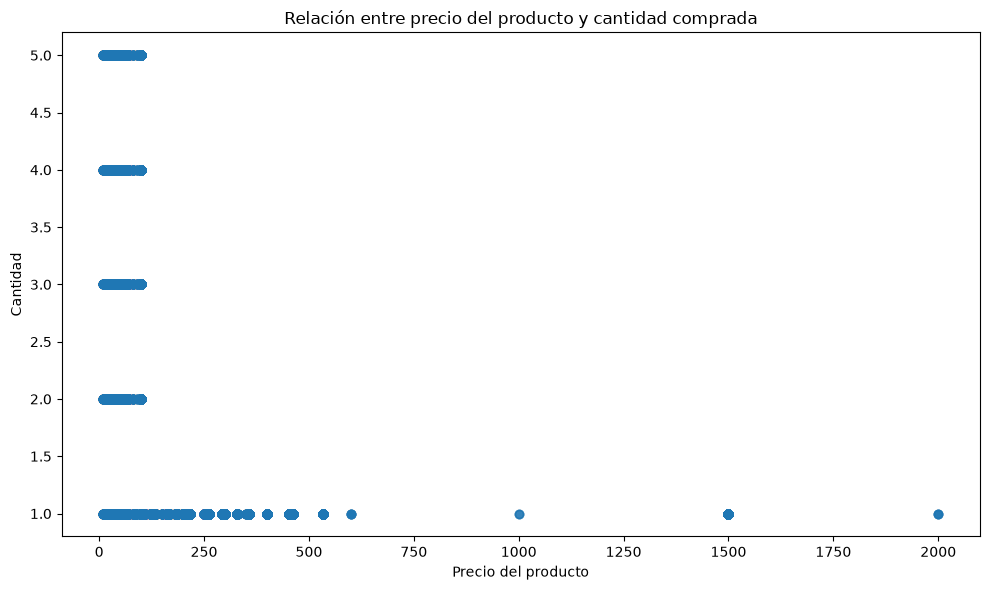

In [172]:
# Comprobamos visualmente la relación entre el precio del producto y la cantidad comprada

plt.figure(figsize=(10, 6))

plt.scatter(
    df["order_item_product_price"],
    df["order_item_quantity"],
    alpha=0.2
)

plt.title("Relación entre precio del producto y cantidad comprada")
plt.xlabel("Precio del producto")
plt.ylabel("Cantidad")
plt.tight_layout()
plt.show()

El gráfico muestra una tendencia negativa entre el precio del producto y la cantidad comprada, coherente con la correlación obtenida (-0,48). En general, los productos con un precio más elevado tienden a presentar una menor cantidad de unidades por operación. No obstante, la relación no es completamente lineal, por lo que el precio no explica por sí solo la cantidad comprada.

Para analizar la relación entre las ventas y el descuento aplicado, se compararán ambas variables mediante un gráfico de dispersión con una línea de tendencia. El objetivo es comprobar si los valores de ventas más elevados tienden a estar asociados con descuentos mayores.

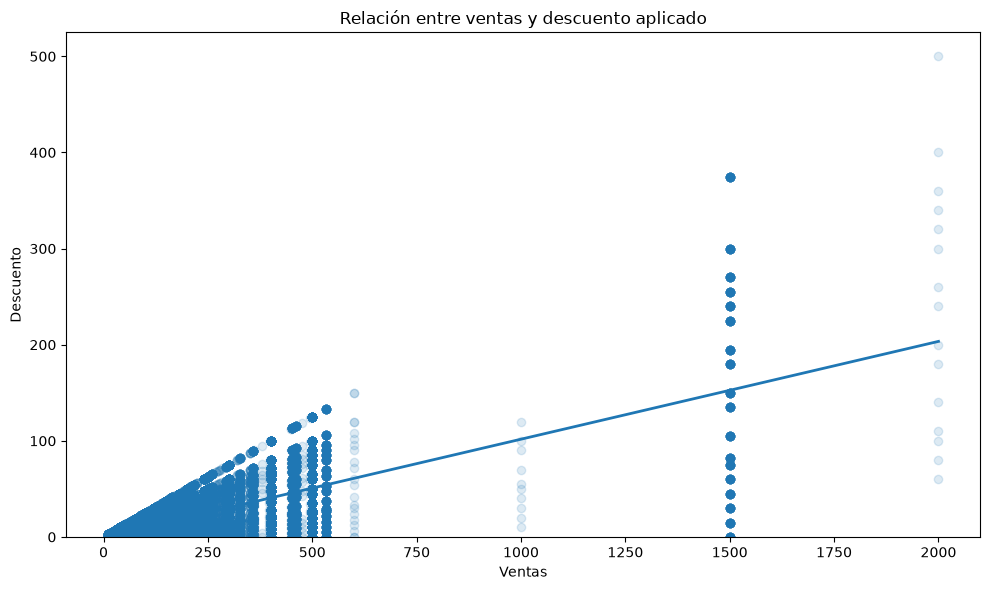

In [173]:
# Comprobamos visualmente la relación entre las ventas y el descuento aplicado

x = df["sales"]
y = df["order_item_discount"]

plt.figure(figsize=(10, 6))

plt.scatter(
    x,
    y,
    alpha=0.15
)

# Calculamos y representamos la línea de tendencia
pendiente, intercepto = np.polyfit(x, y, 1)

x_ordenado = x.sort_values()

plt.plot(
    x_ordenado,
    pendiente * x_ordenado + intercepto,
    linewidth=2
)

plt.title("Relación entre ventas y descuento aplicado")
plt.xlabel("Ventas")
plt.ylabel("Descuento")
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()

El gráfico muestra una tendencia positiva entre las ventas y el descuento aplicado, coherente con la correlación obtenida (0,62). La mayor parte de las operaciones se concentra en niveles bajos de ventas y descuento, aunque también se observan operaciones con valores más elevados. La línea de tendencia confirma que, en general, las operaciones con mayores ventas tienden a presentar descuentos superiores.

Esta relación indica que ambas variables están asociadas, pero no permite afirmar que un mayor descuento provoque directamente un aumento de las ventas, ya que pueden existir otros factores que influyan en ambas variables.

Para analizar si el resultado económico varía entre categorías, se comparará el beneficio medio por operación de cada category_name. El objetivo es identificar si existen categorías con un beneficio medio significativamente diferente al resto.

In [174]:
# Comparamos el beneficio medio por operación entre las diferentes categorías

beneficio_categoria = (
    df.groupby("category_name")["benefit_per_order"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print(beneficio_categoria)

category_name
Computers               157.59
Garden                   69.10
Crafts                   52.75
Cameras                  51.17
Fishing                  43.65
Children's Clothing      41.68
Sporting Goods           35.07
Music                    33.26
Camping & Hiking         31.14
Consumer Electronics     30.68
Cardio Equipment         30.67
Golf Bags & Carts        29.67
Women's Clothing         29.39
Soccer                   28.27
Women's Golf Clubs       27.78
Basketball               27.55
Health and Beauty        26.23
Golf Shoes               23.68
Kids' Golf Clubs         23.56
Water Sports             20.92
Boxing & MMA             20.43
Baseball & Softball      20.19
Cleats                   20.15
Men's Golf Clubs         19.50
Tennis & Racquet         17.52
Fitness Accessories      17.02
Women's Apparel          16.66
Indoor/Outdoor Games     16.50
Girls' Apparel           14.40
Men's Footwear           14.02
DVDs                     13.78
Hunting & Shooting       

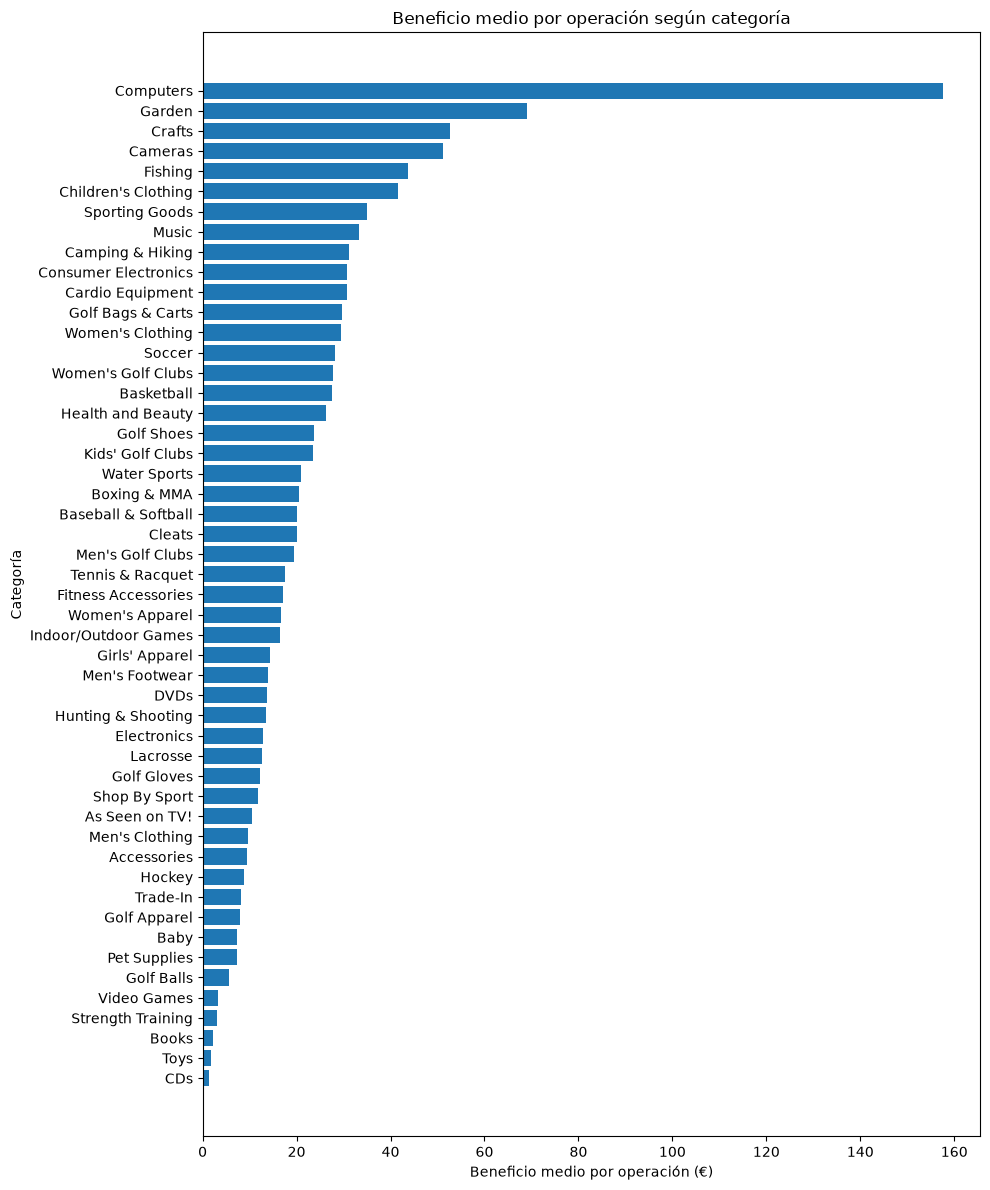

In [175]:
# Representamos el beneficio medio por operación para cada categoría

beneficio_categoria = (
    df.groupby("category_name")["benefit_per_order"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(10, 12))

plt.barh(
    beneficio_categoria.index,
    beneficio_categoria.values
)

plt.title("Beneficio medio por operación según categoría")
plt.xlabel("Beneficio medio por operación (€)")
plt.ylabel("Categoría")
plt.tight_layout()
plt.show()

El análisis muestra diferencias importantes en el beneficio medio por operación entre las distintas categorías. Computers destaca claramente con un beneficio medio de 157,59 €, muy por encima de Garden, que presenta 69,10 €. También destacan Crafts y Cameras, con beneficios medios superiores a 50 €.

En el extremo contrario, categorías como CDs, Toys y Books presentan beneficios medios inferiores a 3 €. Por tanto, el beneficio obtenido por operación varía considerablemente según la categoría, lo que indica que el tipo de producto puede estar relacionado con el resultado económico de las operaciones.

Para analizar si el tiempo de envío varía según la modalidad utilizada, se comparará el número medio de días de envío real entre los diferentes modos de envío. El objetivo es identificar si alguna modalidad presenta tiempos de entrega claramente superiores o inferiores al resto.

In [176]:
# Comparamos el tiempo medio de envío real según la modalidad de envío

tiempo_envio_modalidad = (
    df.groupby("shipping_mode", observed=True)["days_for_shipping_real"]
    .mean()
    .sort_values()
    .round(2)
)

print(tiempo_envio_modalidad)

shipping_mode
Same Day          0.48
First Class       2.00
Second Class      3.99
Standard Class    4.00
Name: days_for_shipping_real, dtype: float64


Para facilitar la comparación entre las diferentes modalidades de envío, se representará gráficamente el tiempo medio de envío real de cada una de ellas.

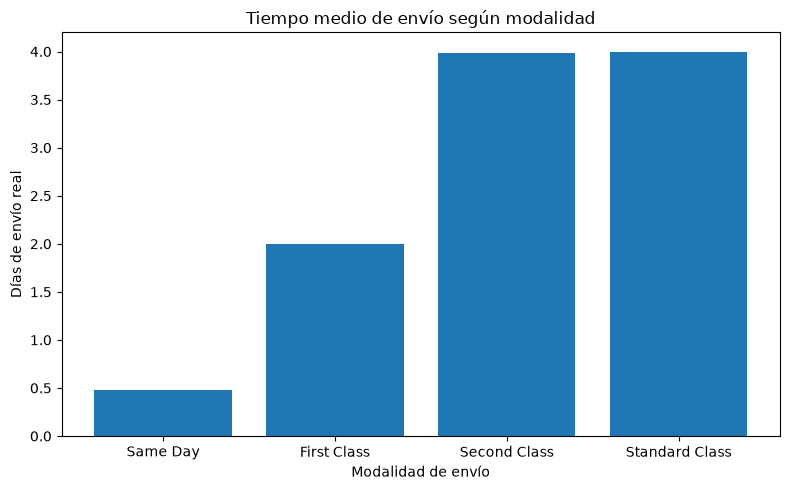

In [177]:
# Representamos el tiempo medio de envío real según la modalidad de envío

plt.figure(figsize=(8, 5))

plt.bar(
    tiempo_envio_modalidad.index,
    tiempo_envio_modalidad.values
)

plt.title("Tiempo medio de envío según modalidad")
plt.xlabel("Modalidad de envío")
plt.ylabel("Días de envío real")
plt.tight_layout()
plt.show()

El tiempo medio de envío presenta diferencias claras según la modalidad utilizada. Same Day es la modalidad más rápida, con una media de 0,48 días, seguida de First Class, con 2 días. Por otro lado, Second Class y Standard Class presentan tiempos medios muy similares, de 3,99 y 4 días respectivamente.

Por tanto, la modalidad de envío está claramente relacionada con el tiempo real de entrega. Las modalidades que ofrecen un servicio más rápido presentan también menores tiempos medios de envío.

Para analizar si el volumen de ventas varía según el mercado, se compararán las ventas medias por operación entre los diferentes mercados. El objetivo es identificar si existen diferencias relevantes en el nivel de ventas asociado a cada mercado.

In [178]:
# Comparamos las ventas medias por operación entre los diferentes mercados

ventas_mercado = (
    df.groupby("market", observed=True)["sales"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print(ventas_mercado)

market
Europe          216.36
Pacific Asia    200.53
LATAM           199.20
Africa          197.56
USCA            196.38
Name: sales, dtype: float64


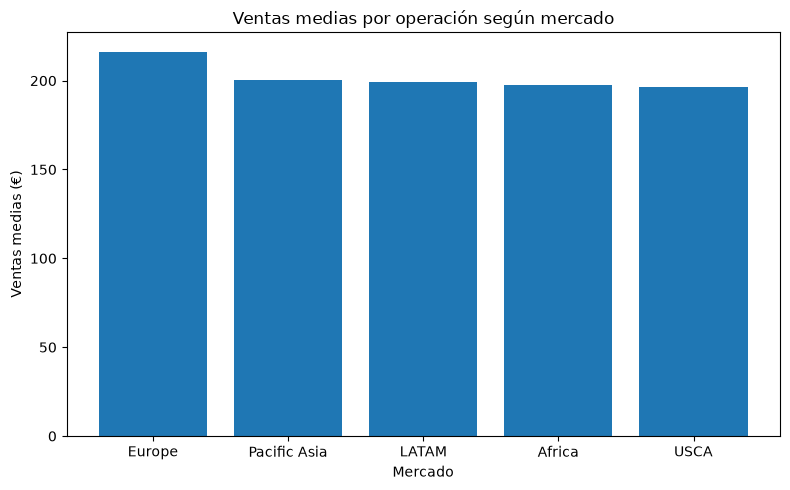

In [179]:
# Representamos las ventas medias por operación según el mercado

plt.figure(figsize=(8, 5))

plt.bar(
    ventas_mercado.index,
    ventas_mercado.values
)

plt.title("Ventas medias por operación según mercado")
plt.xlabel("Mercado")
plt.ylabel("Ventas medias (€)")
plt.tight_layout()
plt.show()

El análisis muestra que existen diferencias en las ventas medias por operación según el mercado. Europa presenta el valor más elevado, con 216,36 € por operación, mientras que USCA registra el valor más bajo, con 196,38 €. Sin embargo, la diferencia entre ambos mercados es relativamente reducida, por lo que el mercado no parece generar diferencias muy importantes en el nivel de ventas por operación.

Para analizar si el resultado económico varía según el tipo de cliente, se comparará el beneficio medio por operación entre los diferentes segmentos de clientes. El objetivo es identificar si alguno de los segmentos presenta diferencias relevantes en el beneficio obtenido.

In [180]:
# Comparamos el beneficio medio por operación entre los diferentes segmentos de clientes

beneficio_segmento = (
    df.groupby("customer_segment", observed=True)["benefit_per_order"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print(beneficio_segmento)

customer_segment
Consumer       22.18
Corporate      21.95
Home Office    21.44
Name: benefit_per_order, dtype: float64


El beneficio medio por operación presenta valores muy similares entre los tres segmentos de clientes. Consumer registra el valor más elevado, con 22,18 €, seguido de Corporate, con 21,95 €, y Home Office, con 21,44 €. La diferencia entre el segmento con mayor y menor beneficio es inferior a 1 € por operación.

Por tanto, el segmento de cliente no parece estar relacionado con diferencias relevantes en el beneficio medio obtenido por operación.

El análisis muestra que las relaciones más relevantes se encuentran en las variables relacionadas con el producto y el envío. El beneficio medio varía notablemente entre categorías, mientras que la modalidad de envío presenta diferencias claras en el tiempo real de entrega.

También se observa una relación positiva entre ventas y descuentos y una relación negativa entre precio y cantidad comprada. En cambio, variables como el mercado o el segmento de cliente presentan diferencias reducidas.

En conjunto, los resultados permiten identificar las variables con mayor relación con el comportamiento económico y logístico de las operaciones.

### Conclusiones del análisis exploratorio

·Ventas: se mantienen estables durante 2015 y 2016, pero presentan una caída importante a finales de 2017 y principios de 2018.

·Rentabilidad: el 18,7 % de las operaciones generan pérdidas, con un impacto acumulado de aproximadamente 3,88 millones de euros. El beneficio medio también presenta diferencias importantes entre categorías.

·Logística: el 54,83 % de las operaciones presentan riesgo de retraso. Las mayores diferencias aparecen según el tipo de envío, especialmente en First Class y Second Class.

·Relaciones: destacan la relación negativa entre precio y cantidad comprada y la relación positiva entre ventas y descuento. También se observan diferencias relevantes en el beneficio según la categoría y en el tiempo de envío según la modalidad.

Se concluye que los principales puntos de atención son la rentabilidad de las categorías, las operaciones con pérdidas y el rendimiento de las distintas modalidades de envío.